### SQL-Abfragen mit SQLite - Übungen

In diesem Notebook übst du **SQL-Abfragen** an der Datenbank eines Kinos: Filme, Säle, Vorstellungen, Kunden und Tickets.
Du schreibst in jede Code-Zelle **eine SQL-Anweisung**. Beim Ausführen erscheint das Ergebnis als Tabelle.
Das Notebook verwendet den Kernel **SQLite** (oben rechts steht „SQLite (xsqlite)“), nicht Python.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Bei jeder Aufgabe siehst du die beteiligten Tabellen und darunter das **erwartete Ergebnis**.
Vergleiche dein Ergebnis damit, auch die Reihenfolge der Zeilen und die Spaltennamen.

**Wichtig:**
- Führe zuerst die Zelle mit `%LOAD kino.db r` aus. Sie öffnet die Datenbank (`r`: nur lesen, du kannst also nichts kaputt machen).
  Musst du das Notebook neu öffnen oder den Kernel neu starten, führe sie wieder aus.
- In jede Zelle gehört **genau eine** Anweisung. Stehen mehrere darin, wird nur die erste ausgeführt.
- Fehlende Werte (`NULL`) erscheinen in der Ergebnistabelle als **leeres Feld**.

**So liest du die Diagramme:** Jeder Kasten ist eine Tabelle mit ihren Spalten. **Unterstrichen** ist der Primärschlüssel,
**↑** markiert einen Fremdschlüssel. An den Verbindungslinien steht die Kardinalität: Eine Linie mit **1** und **n**
bedeutet zum Beispiel, dass zu einem Film (1) viele Vorstellungen (n) gehören.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### Datenbank öffnen

**Führe diese Zelle zuerst aus.** Sie öffnet die Datenbank `kino.db`, die im selben Ordner wie dieses Notebook liegt.

In [ ]:
%LOAD kino.db r

## 1. Die Kino-Datenbank

#### Die Tabellen

Die Datenbank `kino.db` gehört zu einem kleinen Kino mit vier Sälen. Sie enthält den Spielplan einer Woche (2. bis 8. November 2026).

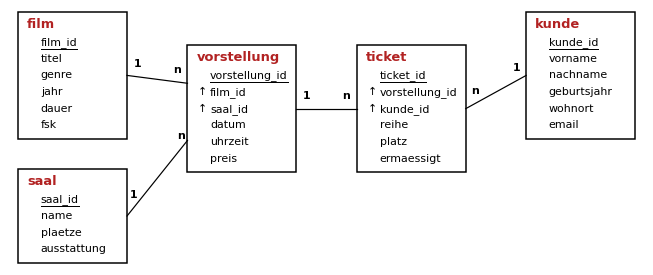

| Tabelle | Inhalt |
|---|---|
| `film` | alle Filme mit Genre, Erscheinungsjahr, Dauer in Minuten und Altersfreigabe (`fsk`) |
| `saal` | die Säle mit Anzahl der Plätze und Ausstattung |
| `vorstellung` | wann welcher Film in welchem Saal läuft, mit Eintrittspreis in Euro |
| `kunde` | die Kunden mit Geburtsjahr, Wohnort und E-Mail-Adresse (nicht alle haben eine) |
| `ticket` | die verkauften Tickets: wer welche Vorstellung besucht, mit Sitzplatz; `ermaessigt` ist 1 oder 0 |

Zwischen `kunde` und `vorstellung` besteht eine **n:m-Beziehung**: Ein Kunde besucht viele Vorstellungen, eine Vorstellung hat viele Besucher.
Sie wird durch die Tabelle `ticket` mit zwei Fremdschlüsseln aufgelöst.

`SELECT * FROM tabelle;` gibt eine ganze Tabelle aus. Der Stern `*` steht für „alle Spalten“.

In [ ]:
SELECT * FROM saal;

#### Welche Tabellen und Spalten gibt es?

SQLite speichert die Beschreibung der Datenbank selbst in einer Tabelle: `sqlite_master` enthält alle Tabellen.
`PRAGMA table_info(film);` zeigt die Spalten einer Tabelle mit ihrem Datentyp; `pk` ist 1 beim Primärschlüssel.

In [ ]:
SELECT name FROM sqlite_master WHERE type = 'table';

#### Aufgabe 1.1

Gib die ganze Tabelle `film` aus.

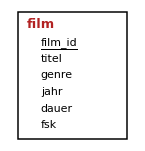

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">film_id</th><th style="text-align: right">titel</th><th style="text-align: right">genre</th><th style="text-align: right">jahr</th><th style="text-align: right">dauer</th><th style="text-align: right">fsk</th></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">Der Leuchtturm am Ende der Welt</td><td style="text-align: right">Drama</td><td style="text-align: right">2024</td><td style="text-align: right">112</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">Galaxis Express</td><td style="text-align: right">Science-Fiction</td><td style="text-align: right">2025</td><td style="text-align: right">128</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">Animation</td><td style="text-align: right">2025</td><td style="text-align: right">89</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">Die letzte Spur</td><td style="text-align: right">Krimi</td><td style="text-align: right">2023</td><td style="text-align: right">104</td><td style="text-align: right">16</td></tr>
<tr><td style="text-align: right">5</td><td style="text-align: right">Sommer in Lissabon</td><td style="text-align: right">Komödie</td><td style="text-align: right">2024</td><td style="text-align: right">97</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">6</td><td style="text-align: right">Robo-Ritter</td><td style="text-align: right">Animation</td><td style="text-align: right">2024</td><td style="text-align: right">92</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">7</td><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">Dokumentation</td><td style="text-align: right">2025</td><td style="text-align: right">85</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">8</td><td style="text-align: right">Kettenreaktion</td><td style="text-align: right">Action</td><td style="text-align: right">2025</td><td style="text-align: right">131</td><td style="text-align: right">16</td></tr>
<tr><td style="text-align: right">9</td><td style="text-align: right">Das Geheimnis der alten Mühle</td><td style="text-align: right">Familie</td><td style="text-align: right">2023</td><td style="text-align: right">95</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">10</td><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Krimi</td><td style="text-align: right">2025</td><td style="text-align: right">118</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">11</td><td style="text-align: right">Wolkenkratzer</td><td style="text-align: right">Action</td><td style="text-align: right">2023</td><td style="text-align: right">124</td><td style="text-align: right">16</td></tr>
<tr><td style="text-align: right">12</td><td style="text-align: right">Planet der Pilze</td><td style="text-align: right">Science-Fiction</td><td style="text-align: right">2024</td><td style="text-align: right">109</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">13</td><td style="text-align: right">Omas großes Abenteuer</td><td style="text-align: right">Komödie</td><td style="text-align: right">2025</td><td style="text-align: right">101</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">14</td><td style="text-align: right">Schattenspiel</td><td style="text-align: right">Horror</td><td style="text-align: right">2024</td><td style="text-align: right">99</td><td style="text-align: right">18</td></tr>
<tr><td style="text-align: right">15</td><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">Dokumentation</td><td style="text-align: right">2023</td><td style="text-align: right">78</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">16</td><td style="text-align: right">Funkstille</td><td style="text-align: right">Drama</td><td style="text-align: right">2025</td><td style="text-align: right">116</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">17</td><td style="text-align: right">Mission Mondbasis</td><td style="text-align: right">Science-Fiction</td><td style="text-align: right">2025</td><td style="text-align: right">135</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">18</td><td style="text-align: right">Der Fluch von Burg Eisenstein</td><td style="text-align: right">Horror</td><td style="text-align: right">2025</td><td style="text-align: right">94</td><td style="text-align: right">16</td></tr>
<tr><td style="text-align: right">19</td><td style="text-align: right">Fußballfieber</td><td style="text-align: right">Komödie</td><td style="text-align: right">2024</td><td style="text-align: right">93</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">20</td><td style="text-align: right">Ein Koffer voller Träume</td><td style="text-align: right">Drama</td><td style="text-align: right">2022</td><td style="text-align: right">121</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">21</td><td style="text-align: right">Zeitreise für Anfänger</td><td style="text-align: right">Komödie</td><td style="text-align: right">2025</td><td style="text-align: right">105</td><td style="text-align: right">12</td></tr>
</table>

*21 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT * FROM film;
```

</details>

#### Aufgabe 1.2

Gib die ganze Tabelle `vorstellung` aus. (Sie ist lang. Schau dir an, wie Datum, Uhrzeit und Preis gespeichert sind.)

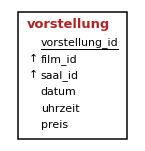

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorstellung_id</th><th style="text-align: right">film_id</th><th style="text-align: right">saal_id</th><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">10</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">14:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">8</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">14:30</td><td style="text-align: right">8.5</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">1</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">17:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">7</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">20:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">5</td><td style="text-align: right">1</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">22:30</td><td style="text-align: right">12.5</td></tr>
<tr><td style="text-align: right">6</td><td style="text-align: right">19</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">22:30</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">7</td><td style="text-align: right">12</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">14:30</td><td style="text-align: right">6.5</td></tr>
<tr><td style="text-align: right">8</td><td style="text-align: right">11</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">14:30</td><td style="text-align: right">12.5</td></tr>
<tr><td style="text-align: right">9</td><td style="text-align: right">19</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">17:00</td><td style="text-align: right">13.5</td></tr>
<tr><td style="text-align: right">10</td><td style="text-align: right">10</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">20:00</td><td style="text-align: right">10.5</td></tr>
<tr><td style="text-align: right">11</td><td style="text-align: right">12</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">20:00</td><td style="text-align: right">7.5</td></tr>
<tr><td style="text-align: right">12</td><td style="text-align: right">19</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">22:30</td><td style="text-align: right">10.5</td></tr>
<tr><td style="text-align: right">13</td><td style="text-align: right">14</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">22:30</td><td style="text-align: right">7.5</td></tr>
<tr><td style="text-align: right">14</td><td style="text-align: right">14</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">14:30</td><td style="text-align: right">14.5</td></tr>
<tr><td style="text-align: right">15</td><td style="text-align: right">2</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">17:00</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">16</td><td style="text-align: right">10</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">17:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">17</td><td style="text-align: right">18</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">20:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">18</td><td style="text-align: right">16</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">22:30</td><td style="text-align: right">12.5</td></tr>
<tr><td style="text-align: right">19</td><td style="text-align: right">8</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">22:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">20</td><td style="text-align: right">19</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">22:30</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">21</td><td style="text-align: right">17</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">22:30</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">22</td><td style="text-align: right">5</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">14:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">23</td><td style="text-align: right">10</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">14:30</td><td style="text-align: right">14.5</td></tr>
<tr><td style="text-align: right">24</td><td style="text-align: right">16</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">20:00</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">25</td><td style="text-align: right">15</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">20:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">26</td><td style="text-align: right">16</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">22:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">27</td><td style="text-align: right">4</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">22:30</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">28</td><td style="text-align: right">12</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">22:30</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">29</td><td style="text-align: right">15</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">30</td><td style="text-align: right">2</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td><td style="text-align: right">10.5</td></tr>
<tr><td style="text-align: right">31</td><td style="text-align: right">14</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">17:00</td><td style="text-align: right">12.5</td></tr>
<tr><td style="text-align: right">32</td><td style="text-align: right">5</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">20:00</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">33</td><td style="text-align: right">1</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">34</td><td style="text-align: right">12</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">35</td><td style="text-align: right">13</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">14:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">36</td><td style="text-align: right">5</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">17:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">37</td><td style="text-align: right">3</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">20:00</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">38</td><td style="text-align: right">1</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">20:00</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">39</td><td style="text-align: right">19</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">22:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">40</td><td style="text-align: right">5</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">22:30</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">41</td><td style="text-align: right">7</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">14:30</td><td style="text-align: right">14.5</td></tr>
<tr><td style="text-align: right">42</td><td style="text-align: right">19</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">17:00</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">43</td><td style="text-align: right">3</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">17:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">44</td><td style="text-align: right">10</td><td style="text-align: right">4</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">20:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">45</td><td style="text-align: right">15</td><td style="text-align: right">1</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">22:30</td><td style="text-align: right">12.5</td></tr>
<tr><td style="text-align: right">46</td><td style="text-align: right">11</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">22:30</td><td style="text-align: right">11.5</td></tr>
</table>

*46 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT * FROM vorstellung;
```

</details>

#### Aufgabe 1.3

Gib mit `PRAGMA table_info(...)` die Spalten der Tabelle `ticket` aus.

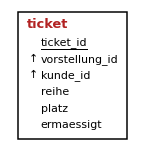

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">cid</th><th style="text-align: right">name</th><th style="text-align: right">type</th><th style="text-align: right">notnull</th><th style="text-align: right">dflt_value</th><th style="text-align: right">pk</th></tr>
<tr><td style="text-align: right">0</td><td style="text-align: right">ticket_id</td><td style="text-align: right">INTEGER</td><td style="text-align: right">0</td><td style="text-align: right"></td><td style="text-align: right">1</td></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">vorstellung_id</td><td style="text-align: right">INTEGER</td><td style="text-align: right">1</td><td style="text-align: right"></td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">kunde_id</td><td style="text-align: right">INTEGER</td><td style="text-align: right">1</td><td style="text-align: right"></td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">reihe</td><td style="text-align: right">INTEGER</td><td style="text-align: right">1</td><td style="text-align: right"></td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">platz</td><td style="text-align: right">INTEGER</td><td style="text-align: right">1</td><td style="text-align: right"></td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">5</td><td style="text-align: right">ermaessigt</td><td style="text-align: right">INTEGER</td><td style="text-align: right">1</td><td style="text-align: right"></td><td style="text-align: right">0</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
PRAGMA table_info(ticket);
```

</details>

#### Aufgabe 1.4

Gib die Namen aller Tabellen aus, die es in der Datenbank gibt.

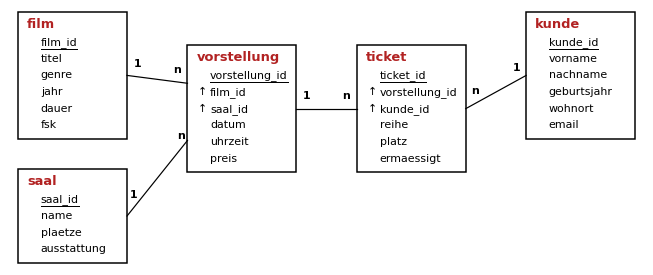

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th></tr>
<tr><td style="text-align: right">film</td></tr>
<tr><td style="text-align: right">saal</td></tr>
<tr><td style="text-align: right">vorstellung</td></tr>
<tr><td style="text-align: right">kunde</td></tr>
<tr><td style="text-align: right">ticket</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT name FROM sqlite_master WHERE type = 'table';
```

</details>

## 2. Spalten auswählen

#### `SELECT spalte1, spalte2 FROM tabelle`

Statt `*` gibt man die gewünschten Spalten mit Komma getrennt an. Sie erscheinen in dieser Reihenfolge.

- Mit `AS` gibt man einer Spalte im Ergebnis einen anderen Namen: `SELECT name AS saal FROM saal;`
- Man kann auch **rechnen**: `plaetze * 2`, `dauer / 60.0`. Achtung: Teilt man zwei ganze Zahlen, ist das Ergebnis ganzzahlig (`7 / 2` ist `3`).
  Mit `60.0` statt `60` wird mit Kommazahlen gerechnet. `ROUND(x, 2)` rundet auf zwei Nachkommastellen.
- `||` hängt Texte aneinander: `vorname || ' ' || nachname`. Texte stehen in **einfachen** Anführungszeichen.
- `LIMIT 5` am Ende gibt nur die ersten 5 Zeilen aus.

In [ ]:
SELECT titel, dauer, ROUND(dauer / 60.0, 2) AS stunden
FROM film
LIMIT 5;

#### `DISTINCT`

`SELECT DISTINCT spalte FROM tabelle;` gibt jeden Wert nur **einmal** aus, auch wenn er in mehreren Zeilen vorkommt.

In [ ]:
SELECT DISTINCT wohnort FROM kunde;

#### Aufgabe 2.1

Gib Name und Anzahl der Plätze aller Säle aus.

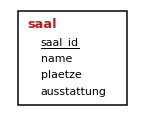

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th><th style="text-align: right">plaetze</th></tr>
<tr><td style="text-align: right">Großer Saal</td><td style="text-align: right">220</td></tr>
<tr><td style="text-align: right">Blauer Saal</td><td style="text-align: right">140</td></tr>
<tr><td style="text-align: right">Roter Saal</td><td style="text-align: right">90</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">40</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT name, plaetze FROM saal;
```

</details>

#### Aufgabe 2.2

Gib Vorname und Nachname der ersten 5 Kunden aus.

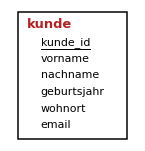

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Lena</td><td style="text-align: right">Hoffmann</td></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">Becker</td></tr>
<tr><td style="text-align: right">Mia</td><td style="text-align: right">Schulz</td></tr>
<tr><td style="text-align: right">Paul</td><td style="text-align: right">Wagner</td></tr>
<tr><td style="text-align: right">Emma</td><td style="text-align: right">Fischer</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname FROM kunde LIMIT 5;
```

</details>

#### Aufgabe 2.3

Gib Titel und Erscheinungsjahr der ersten 8 Filme aus. Die Spalten sollen im Ergebnis `Film` und `Jahr` heißen.

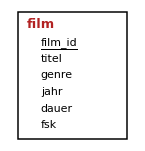

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">Film</th><th style="text-align: right">Jahr</th></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td><td style="text-align: right">2024</td></tr>
<tr><td style="text-align: right">Galaxis Express</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Die letzte Spur</td><td style="text-align: right">2023</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td><td style="text-align: right">2024</td></tr>
<tr><td style="text-align: right">Robo-Ritter</td><td style="text-align: right">2024</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Kettenreaktion</td><td style="text-align: right">2025</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel AS Film, jahr AS Jahr FROM film LIMIT 8;
```

</details>

#### Aufgabe 2.4

Gib für jeden Saal den Namen und die Anzahl der Plätze mit 10 zusätzlichen Notsitzen aus. Die zweite Spalte soll `mit_notsitzen` heißen.

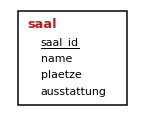

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th><th style="text-align: right">mit_notsitzen</th></tr>
<tr><td style="text-align: right">Großer Saal</td><td style="text-align: right">230</td></tr>
<tr><td style="text-align: right">Blauer Saal</td><td style="text-align: right">150</td></tr>
<tr><td style="text-align: right">Roter Saal</td><td style="text-align: right">100</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">50</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT name, plaetze + 10 AS mit_notsitzen FROM saal;
```

</details>

#### Aufgabe 2.5

Gib für die ersten 5 Filme den Titel und die Dauer in Stunden aus, gerundet auf zwei Nachkommastellen (Spaltenname `stunden`).

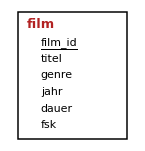

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">stunden</th></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td><td style="text-align: right">1.87</td></tr>
<tr><td style="text-align: right">Galaxis Express</td><td style="text-align: right">2.13</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">1.48</td></tr>
<tr><td style="text-align: right">Die letzte Spur</td><td style="text-align: right">1.73</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td><td style="text-align: right">1.62</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, ROUND(dauer / 60.0, 2) AS stunden FROM film LIMIT 5;
```

</details>

#### Aufgabe 2.6

Gib für die ersten 6 Kunden den ganzen Namen in **einer** Spalte `name` aus, z. B. `Lena Hoffmann`.

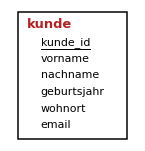

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th></tr>
<tr><td style="text-align: right">Lena Hoffmann</td></tr>
<tr><td style="text-align: right">Jonas Becker</td></tr>
<tr><td style="text-align: right">Mia Schulz</td></tr>
<tr><td style="text-align: right">Paul Wagner</td></tr>
<tr><td style="text-align: right">Emma Fischer</td></tr>
<tr><td style="text-align: right">Ben Weber</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname || ' ' || nachname AS name FROM kunde LIMIT 6;
```

</details>

#### Aufgabe 2.7

Gib alle Genres aus, jedes nur einmal.

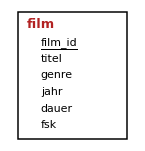

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th></tr>
<tr><td style="text-align: right">Drama</td></tr>
<tr><td style="text-align: right">Science-Fiction</td></tr>
<tr><td style="text-align: right">Animation</td></tr>
<tr><td style="text-align: right">Krimi</td></tr>
<tr><td style="text-align: right">Komödie</td></tr>
<tr><td style="text-align: right">Dokumentation</td></tr>
<tr><td style="text-align: right">Action</td></tr>
<tr><td style="text-align: right">Familie</td></tr>
<tr><td style="text-align: right">Horror</td></tr>
</table>

*9 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT genre FROM film;
```

</details>

#### Aufgabe 2.8

Gib alle Tage aus, an denen Vorstellungen stattfinden, jeden nur einmal.

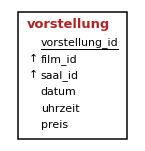

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th></tr>
<tr><td style="text-align: right">2026-11-02</td></tr>
<tr><td style="text-align: right">2026-11-03</td></tr>
<tr><td style="text-align: right">2026-11-04</td></tr>
<tr><td style="text-align: right">2026-11-05</td></tr>
<tr><td style="text-align: right">2026-11-06</td></tr>
<tr><td style="text-align: right">2026-11-07</td></tr>
<tr><td style="text-align: right">2026-11-08</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT datum FROM vorstellung;
```

</details>

#### Aufgabe 2.9

Gib alle Uhrzeiten aus, zu denen Vorstellungen beginnen, jede nur einmal.

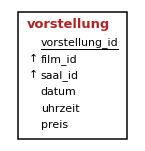

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">uhrzeit</th></tr>
<tr><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">17:00</td></tr>
<tr><td style="text-align: right">20:00</td></tr>
<tr><td style="text-align: right">22:30</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT uhrzeit FROM vorstellung;
```

</details>

#### Aufgabe 2.10

Gib für die ersten 5 Vorstellungen Datum, Uhrzeit, Preis und den Preis für eine Familie mit 4 Personen (Spalte `familie`) aus.

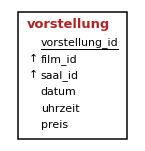

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th><th style="text-align: right">preis</th><th style="text-align: right">familie</th></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">14:30</td><td style="text-align: right">11.5</td><td style="text-align: right">46.0</td></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">14:30</td><td style="text-align: right">8.5</td><td style="text-align: right">34.0</td></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">17:00</td><td style="text-align: right">15.5</td><td style="text-align: right">62.0</td></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">20:00</td><td style="text-align: right">15.5</td><td style="text-align: right">62.0</td></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">22:30</td><td style="text-align: right">12.5</td><td style="text-align: right">50.0</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT datum, uhrzeit, preis, preis * 4 AS familie FROM vorstellung LIMIT 5;
```

</details>

#### Aufgabe 2.11

Gib für die ersten 5 Kunden Vorname, Nachname und das Alter im Jahr 2026 (Spalte `alter_2026`) aus.

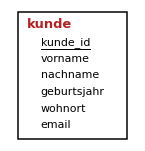

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">alter_2026</th></tr>
<tr><td style="text-align: right">Lena</td><td style="text-align: right">Hoffmann</td><td style="text-align: right">17</td></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">Becker</td><td style="text-align: right">18</td></tr>
<tr><td style="text-align: right">Mia</td><td style="text-align: right">Schulz</td><td style="text-align: right">15</td></tr>
<tr><td style="text-align: right">Paul</td><td style="text-align: right">Wagner</td><td style="text-align: right">51</td></tr>
<tr><td style="text-align: right">Emma</td><td style="text-align: right">Fischer</td><td style="text-align: right">44</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname, 2026 - geburtsjahr AS alter_2026 FROM kunde LIMIT 5;
```

</details>

#### Aufgabe 2.12

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT 3 + 4 * 2 AS a, 7 / 2 AS b, 7 / 2.0 AS c, 7 % 2 AS d;
```

In [ ]:
SELECT 3 + 4 * 2 AS a, 7 / 2 AS b, 7 / 2.0 AS c, 7 % 2 AS d;

## 3. Zeilen auswählen mit WHERE

#### Bedingungen

Mit `WHERE` gibt man nur die Zeilen aus, die eine Bedingung erfüllen.

| Zeichen | Bedeutung |
|---|---|
| `=`, `<>` | gleich, ungleich (`!=` geht auch) |
| `<`, `>`, `<=`, `>=` | kleiner, größer, ... |
| `AND`, `OR`, `NOT` | und, oder, nicht |
| `BETWEEN a AND b` | zwischen a und b (beide einschließlich) |
| `IN ('a', 'b', 'c')` | einer der Werte in der Liste |

Texte und Datumsangaben stehen in einfachen Anführungszeichen: `WHERE genre = 'Krimi'`, `WHERE datum = '2026-11-03'`.
Weil Datum (`2026-11-03`) und Uhrzeit (`20:00`) so gespeichert sind, kann man sie auch mit `<` und `>` vergleichen.

In [ ]:
SELECT titel, jahr, fsk
FROM film
WHERE jahr = 2025 AND fsk <= 6;

#### `LIKE` und `NULL`

- `LIKE` vergleicht mit einem **Muster**: `%` steht für beliebig viele Zeichen, `_` für genau ein Zeichen.
  `titel LIKE 'Die %'` sind alle Titel, die mit „Die “ beginnen. Groß- und Kleinschreibung spielt bei `LIKE` keine Rolle (bei Umlauten schon).
- `NULL` bedeutet „kein Wert“. Ob ein Wert fehlt, prüft man mit `IS NULL` bzw. `IS NOT NULL`, **nicht** mit `= NULL`.

In [ ]:
SELECT vorname, nachname, email
FROM kunde
WHERE nachname LIKE 'S%';

#### Aufgabe 3.1

Gib die Titel aller Komödien aus.

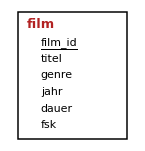

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td></tr>
<tr><td style="text-align: right">Omas großes Abenteuer</td></tr>
<tr><td style="text-align: right">Fußballfieber</td></tr>
<tr><td style="text-align: right">Zeitreise für Anfänger</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel FROM film WHERE genre = 'Komödie';
```

</details>

#### Aufgabe 3.2

Gib Titel und Dauer aller Filme aus, die länger als 120 Minuten sind.

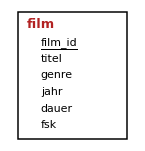

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">dauer</th></tr>
<tr><td style="text-align: right">Galaxis Express</td><td style="text-align: right">128</td></tr>
<tr><td style="text-align: right">Kettenreaktion</td><td style="text-align: right">131</td></tr>
<tr><td style="text-align: right">Wolkenkratzer</td><td style="text-align: right">124</td></tr>
<tr><td style="text-align: right">Mission Mondbasis</td><td style="text-align: right">135</td></tr>
<tr><td style="text-align: right">Ein Koffer voller Träume</td><td style="text-align: right">121</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, dauer FROM film WHERE dauer > 120;
```

</details>

#### Aufgabe 3.3

Gib die Titel aller Filme ohne Altersbeschränkung (FSK 0) aus.

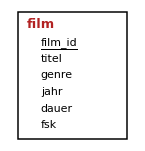

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td></tr>
<tr><td style="text-align: right">Omas großes Abenteuer</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel FROM film WHERE fsk = 0;
```

</details>

#### Aufgabe 3.4

Gib Vorname und Nachname aller Kunden aus Greven aus.

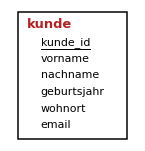

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">Becker</td></tr>
<tr><td style="text-align: right">Hannah</td><td style="text-align: right">Koch</td></tr>
<tr><td style="text-align: right">Clara</td><td style="text-align: right">Schwarz</td></tr>
<tr><td style="text-align: right">Frieda</td><td style="text-align: right">Lange</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname FROM kunde WHERE wohnort = 'Greven';
```

</details>

#### Aufgabe 3.5

Gib für alle Vorstellungen am 4. November 2026 die Uhrzeit, die Film-Nummer und die Saal-Nummer aus.

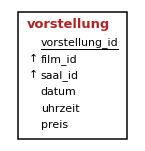

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">uhrzeit</th><th style="text-align: right">film_id</th><th style="text-align: right">saal_id</th></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">14</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">17:00</td><td style="text-align: right">2</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">17:00</td><td style="text-align: right">10</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">18</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">16</td><td style="text-align: right">1</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">8</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">19</td><td style="text-align: right">3</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">17</td><td style="text-align: right">4</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT uhrzeit, film_id, saal_id FROM vorstellung WHERE datum = '2026-11-04';
```

</details>

#### Aufgabe 3.6

Gib die Titel aller Filme aus dem Jahr 2025 mit FSK 12 aus.

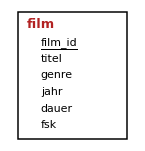

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Galaxis Express</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td></tr>
<tr><td style="text-align: right">Funkstille</td></tr>
<tr><td style="text-align: right">Mission Mondbasis</td></tr>
<tr><td style="text-align: right">Zeitreise für Anfänger</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel FROM film WHERE jahr = 2025 AND fsk = 12;
```

</details>

#### Aufgabe 3.7

Gib Titel und Genre aller Horrorfilme und Krimis aus. Verwende `OR`.

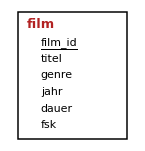

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">genre</th></tr>
<tr><td style="text-align: right">Die letzte Spur</td><td style="text-align: right">Krimi</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Krimi</td></tr>
<tr><td style="text-align: right">Schattenspiel</td><td style="text-align: right">Horror</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td><td style="text-align: right">Horror</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, genre FROM film WHERE genre = 'Horror' OR genre = 'Krimi';
```

</details>

#### Aufgabe 3.8

Gib Titel und Genre aller Horrorfilme und Krimis aus. Verwende diesmal `IN`.

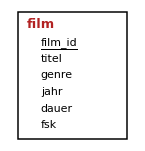

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">genre</th></tr>
<tr><td style="text-align: right">Die letzte Spur</td><td style="text-align: right">Krimi</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Krimi</td></tr>
<tr><td style="text-align: right">Schattenspiel</td><td style="text-align: right">Horror</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td><td style="text-align: right">Horror</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, genre FROM film WHERE genre IN ('Horror', 'Krimi');
```

</details>

#### Aufgabe 3.9

Gib Vorname, Nachname und Geburtsjahr aller Kunden aus, die von 2000 bis 2009 geboren sind. Verwende `BETWEEN`.

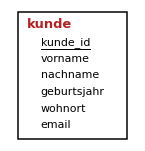

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">geburtsjahr</th></tr>
<tr><td style="text-align: right">Lena</td><td style="text-align: right">Hoffmann</td><td style="text-align: right">2009</td></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">Becker</td><td style="text-align: right">2008</td></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td><td style="text-align: right">2007</td></tr>
<tr><td style="text-align: right">Lea</td><td style="text-align: right">Klein</td><td style="text-align: right">2006</td></tr>
<tr><td style="text-align: right">Luca</td><td style="text-align: right">Neumann</td><td style="text-align: right">2004</td></tr>
<tr><td style="text-align: right">Felix</td><td style="text-align: right">Zimmermann</td><td style="text-align: right">2009</td></tr>
<tr><td style="text-align: right">Leon</td><td style="text-align: right">Krüger</td><td style="text-align: right">2002</td></tr>
<tr><td style="text-align: right">Theo</td><td style="text-align: right">Schmitt</td><td style="text-align: right">2008</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname, geburtsjahr FROM kunde WHERE geburtsjahr BETWEEN 2000 AND 2009;
```

</details>

#### Aufgabe 3.10

Gib Vorname, Nachname und Wohnort aller Kunden aus Telgte, Senden oder Havixbeck aus.

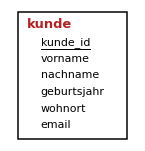

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">wohnort</th></tr>
<tr><td style="text-align: right">Paul</td><td style="text-align: right">Wagner</td><td style="text-align: right">Telgte</td></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td><td style="text-align: right">Senden</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">Havixbeck</td></tr>
<tr><td style="text-align: right">Lea</td><td style="text-align: right">Klein</td><td style="text-align: right">Telgte</td></tr>
<tr><td style="text-align: right">Luca</td><td style="text-align: right">Neumann</td><td style="text-align: right">Senden</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Havixbeck</td></tr>
<tr><td style="text-align: right">Ella</td><td style="text-align: right">Hofmann</td><td style="text-align: right">Telgte</td></tr>
<tr><td style="text-align: right">Lina</td><td style="text-align: right">Werner</td><td style="text-align: right">Senden</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname, wohnort FROM kunde WHERE wohnort IN ('Telgte', 'Senden', 'Havixbeck');
```

</details>

#### Aufgabe 3.11

Gib die Titel aller Filme aus, die mit „Die “ beginnen.

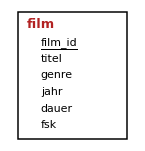

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Die letzte Spur</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td></tr>
</table>

*2 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel FROM film WHERE titel LIKE 'Die %';
```

</details>

#### Aufgabe 3.12

Gib die Nachnamen aller Kunden aus, die auf „er“ enden.

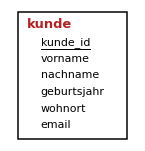

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Becker</td></tr>
<tr><td style="text-align: right">Wagner</td></tr>
<tr><td style="text-align: right">Fischer</td></tr>
<tr><td style="text-align: right">Weber</td></tr>
<tr><td style="text-align: right">Meyer</td></tr>
<tr><td style="text-align: right">Schneider</td></tr>
<tr><td style="text-align: right">Richter</td></tr>
<tr><td style="text-align: right">Schröder</td></tr>
<tr><td style="text-align: right">Krüger</td></tr>
<tr><td style="text-align: right">Werner</td></tr>
</table>

*10 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT nachname FROM kunde WHERE nachname LIKE '%er';
```

</details>

#### Aufgabe 3.13

Gib die Titel aller Filme aus, in deren Titel das Wort „der“ vorkommt (auch „Der“ am Anfang).

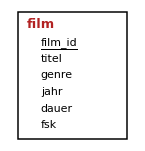

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td></tr>
<tr><td style="text-align: right">Das Geheimnis der alten Mühle</td></tr>
<tr><td style="text-align: right">Planet der Pilze</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel FROM film WHERE titel LIKE '%der %';
```

</details>

#### Aufgabe 3.14

Gib Vorname und Nachname aller Kunden aus, die **keine** E-Mail-Adresse haben.

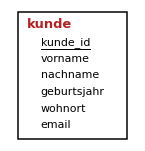

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Mia</td><td style="text-align: right">Schulz</td></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td></tr>
<tr><td style="text-align: right">Finn</td><td style="text-align: right">Wolf</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td></tr>
<tr><td style="text-align: right">Ella</td><td style="text-align: right">Hofmann</td></tr>
<tr><td style="text-align: right">Lina</td><td style="text-align: right">Werner</td></tr>
<tr><td style="text-align: right">Karl</td><td style="text-align: right">Krause</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname FROM kunde WHERE email IS NULL;
```

</details>

#### Aufgabe 3.15

Gib Vorname, Nachname und E-Mail aller Kunden aus Münster aus, die eine E-Mail-Adresse haben.

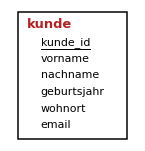

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">email</th></tr>
<tr><td style="text-align: right">Lena</td><td style="text-align: right">Hoffmann</td><td style="text-align: right">lena.h@example.de</td></tr>
<tr><td style="text-align: right">Emma</td><td style="text-align: right">Fischer</td><td style="text-align: right">emma.fischer@example.de</td></tr>
<tr><td style="text-align: right">Sophie</td><td style="text-align: right">Meyer</td><td style="text-align: right">sophie.m@example.de</td></tr>
<tr><td style="text-align: right">Elias</td><td style="text-align: right">Richter</td><td style="text-align: right">elias.r@example.de</td></tr>
<tr><td style="text-align: right">Marie</td><td style="text-align: right">Schröder</td><td style="text-align: right">marie.schroeder@example.de</td></tr>
<tr><td style="text-align: right">Felix</td><td style="text-align: right">Zimmermann</td><td style="text-align: right">felix.z@example.de</td></tr>
<tr><td style="text-align: right">Leon</td><td style="text-align: right">Krüger</td><td style="text-align: right">leon.krueger@example.de</td></tr>
<tr><td style="text-align: right">Anton</td><td style="text-align: right">Hartmann</td><td style="text-align: right">anton.hartmann@example.de</td></tr>
<tr><td style="text-align: right">Theo</td><td style="text-align: right">Schmitt</td><td style="text-align: right">theo.s@example.de</td></tr>
</table>

*9 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname, email FROM kunde WHERE wohnort = 'Münster' AND email IS NOT NULL;
```

</details>

#### Aufgabe 3.16

Gib alle Vorstellungen (alle Spalten) am 6. November aus, die um 20:00 Uhr oder später beginnen.

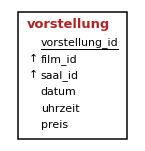

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorstellung_id</th><th style="text-align: right">film_id</th><th style="text-align: right">saal_id</th><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">32</td><td style="text-align: right">5</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">20:00</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">33</td><td style="text-align: right">1</td><td style="text-align: right">2</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">34</td><td style="text-align: right">12</td><td style="text-align: right">3</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">9.5</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT * FROM vorstellung WHERE datum = '2026-11-06' AND uhrzeit >= '20:00';
```

</details>

#### Aufgabe 3.17

Gib Titel, Genre und FSK aller Filme aus, die **keine** Komödie sind und FSK unter 12 haben. Verwende `NOT`.

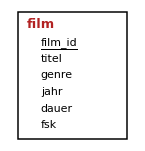

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">genre</th><th style="text-align: right">fsk</th></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">Animation</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">Robo-Ritter</td><td style="text-align: right">Animation</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">Dokumentation</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">Das Geheimnis der alten Mühle</td><td style="text-align: right">Familie</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">Dokumentation</td><td style="text-align: right">0</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, genre, fsk FROM film WHERE NOT genre = 'Komödie' AND fsk < 12;
```

</details>

#### Aufgabe 3.18

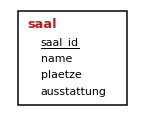

Inhalt der Tabelle `saal`:

<table style="margin-left: 0">
<tr><th style="text-align: right">saal_id</th><th style="text-align: right">name</th><th style="text-align: right">plaetze</th><th style="text-align: right">ausstattung</th></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">Großer Saal</td><td style="text-align: right">220</td><td style="text-align: right">IMAX</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">Blauer Saal</td><td style="text-align: right">140</td><td style="text-align: right">3D</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">Roter Saal</td><td style="text-align: right">90</td><td style="text-align: right">Standard</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">Lounge</td><td style="text-align: right">40</td><td style="text-align: right">Lounge</td></tr>
</table>

*4 Zeilen*

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT name FROM saal WHERE plaetze > 100 AND ausstattung = 'Standard';
```

In [ ]:
SELECT name FROM saal WHERE plaetze > 100 AND ausstattung = 'Standard';

#### Aufgabe 3.19

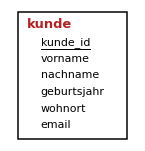

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT vorname FROM kunde WHERE email = NULL;
```

In [ ]:
SELECT vorname FROM kunde WHERE email = NULL;

## 4. Sortieren und begrenzen

#### `ORDER BY` und `LIMIT`

- `ORDER BY spalte` sortiert aufsteigend (`ASC`, das ist der Standard), `ORDER BY spalte DESC` absteigend.
- Mit mehreren Spalten wird zuerst nach der ersten sortiert, bei Gleichheit nach der zweiten: `ORDER BY nachname, vorname`.
- `LIMIT n` gibt nur die ersten `n` Zeilen aus, `LIMIT n OFFSET k` überspringt vorher `k` Zeilen.

Die Reihenfolge der Teile ist fest: `SELECT ... FROM ... WHERE ... ORDER BY ... LIMIT ...`

In [ ]:
SELECT titel, dauer
FROM film
ORDER BY dauer DESC
LIMIT 3;

#### Aufgabe 4.1

Gib Name und Plätze aller Säle aus, den größten Saal zuerst.

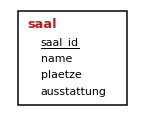

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th><th style="text-align: right">plaetze</th></tr>
<tr><td style="text-align: right">Großer Saal</td><td style="text-align: right">220</td></tr>
<tr><td style="text-align: right">Blauer Saal</td><td style="text-align: right">140</td></tr>
<tr><td style="text-align: right">Roter Saal</td><td style="text-align: right">90</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">40</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT name, plaetze FROM saal ORDER BY plaetze DESC;
```

</details>

#### Aufgabe 4.2

Gib Titel und Dauer der 5 kürzesten Filme aus, den kürzesten zuerst.

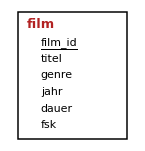

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">dauer</th></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">78</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">85</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">89</td></tr>
<tr><td style="text-align: right">Robo-Ritter</td><td style="text-align: right">92</td></tr>
<tr><td style="text-align: right">Fußballfieber</td><td style="text-align: right">93</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, dauer FROM film ORDER BY dauer LIMIT 5;
```

</details>

#### Aufgabe 4.3

Gib Vorname und Nachname aller Kunden aus Münster aus, sortiert nach Nachname.

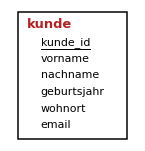

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Emma</td><td style="text-align: right">Fischer</td></tr>
<tr><td style="text-align: right">Anton</td><td style="text-align: right">Hartmann</td></tr>
<tr><td style="text-align: right">Lena</td><td style="text-align: right">Hoffmann</td></tr>
<tr><td style="text-align: right">Karl</td><td style="text-align: right">Krause</td></tr>
<tr><td style="text-align: right">Leon</td><td style="text-align: right">Krüger</td></tr>
<tr><td style="text-align: right">Sophie</td><td style="text-align: right">Meyer</td></tr>
<tr><td style="text-align: right">Elias</td><td style="text-align: right">Richter</td></tr>
<tr><td style="text-align: right">Theo</td><td style="text-align: right">Schmitt</td></tr>
<tr><td style="text-align: right">Marie</td><td style="text-align: right">Schröder</td></tr>
<tr><td style="text-align: right">Mia</td><td style="text-align: right">Schulz</td></tr>
<tr><td style="text-align: right">Finn</td><td style="text-align: right">Wolf</td></tr>
<tr><td style="text-align: right">Felix</td><td style="text-align: right">Zimmermann</td></tr>
</table>

*12 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname FROM kunde WHERE wohnort = 'Münster' ORDER BY nachname;
```

</details>

#### Aufgabe 4.4

Gib Uhrzeit, Film-Nummer und Preis aller Vorstellungen am 7. November aus, nach Uhrzeit sortiert, bei gleicher Uhrzeit nach Preis.

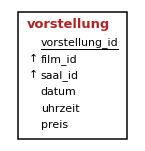

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">uhrzeit</th><th style="text-align: right">film_id</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">13</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">17:00</td><td style="text-align: right">5</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">1</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">3</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">5</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">19</td><td style="text-align: right">11.5</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT uhrzeit, film_id, preis FROM vorstellung WHERE datum = '2026-11-07' ORDER BY uhrzeit, preis;
```

</details>

#### Aufgabe 4.5

Gib Vorname, Nachname und Geburtsjahr der 5 jüngsten Kunden aus. Bei gleichem Geburtsjahr soll nach Nachname sortiert werden.

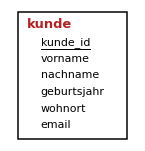

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">geburtsjahr</th></tr>
<tr><td style="text-align: right">Finn</td><td style="text-align: right">Wolf</td><td style="text-align: right">2012</td></tr>
<tr><td style="text-align: right">Mia</td><td style="text-align: right">Schulz</td><td style="text-align: right">2011</td></tr>
<tr><td style="text-align: right">Ella</td><td style="text-align: right">Hofmann</td><td style="text-align: right">2010</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">2010</td></tr>
<tr><td style="text-align: right">Lena</td><td style="text-align: right">Hoffmann</td><td style="text-align: right">2009</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname, geburtsjahr FROM kunde ORDER BY geburtsjahr DESC, nachname LIMIT 5;
```

</details>

#### Aufgabe 4.6

Gib Titel, Genre und Jahr aller Filme aus 2025 aus, nach Genre sortiert und innerhalb eines Genres nach Titel.

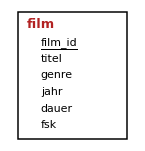

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">genre</th><th style="text-align: right">jahr</th></tr>
<tr><td style="text-align: right">Kettenreaktion</td><td style="text-align: right">Action</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">Animation</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">Dokumentation</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Funkstille</td><td style="text-align: right">Drama</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td><td style="text-align: right">Horror</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Omas großes Abenteuer</td><td style="text-align: right">Komödie</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Zeitreise für Anfänger</td><td style="text-align: right">Komödie</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Krimi</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Galaxis Express</td><td style="text-align: right">Science-Fiction</td><td style="text-align: right">2025</td></tr>
<tr><td style="text-align: right">Mission Mondbasis</td><td style="text-align: right">Science-Fiction</td><td style="text-align: right">2025</td></tr>
</table>

*10 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, genre, jahr FROM film WHERE jahr = 2025 ORDER BY genre, titel;
```

</details>

#### Aufgabe 4.7

Gib die Plätze 4 bis 6 der Rangliste der längsten Filme aus (Titel und Dauer). Verwende `OFFSET`.

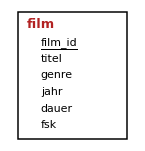

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">dauer</th></tr>
<tr><td style="text-align: right">Wolkenkratzer</td><td style="text-align: right">124</td></tr>
<tr><td style="text-align: right">Ein Koffer voller Träume</td><td style="text-align: right">121</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">118</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, dauer FROM film ORDER BY dauer DESC LIMIT 3 OFFSET 3;
```

</details>

#### Aufgabe 4.8

Gib Datum, Uhrzeit und Preis der 3 teuersten Vorstellungen aus. Bei gleichem Preis die frühere zuerst (nach Datum, dann Uhrzeit).

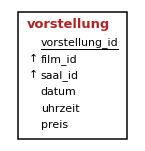

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">17:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">20:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">22:30</td><td style="text-align: right">15.5</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT datum, uhrzeit, preis FROM vorstellung ORDER BY preis DESC, datum, uhrzeit LIMIT 3;
```

</details>

#### Aufgabe 4.9

Gib alle Wohnorte jeweils einmal in alphabetischer Reihenfolge aus.

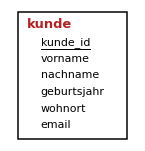

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">wohnort</th></tr>
<tr><td style="text-align: right">Greven</td></tr>
<tr><td style="text-align: right">Havixbeck</td></tr>
<tr><td style="text-align: right">Münster</td></tr>
<tr><td style="text-align: right">Senden</td></tr>
<tr><td style="text-align: right">Telgte</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT wohnort FROM kunde ORDER BY wohnort;
```

</details>

#### Aufgabe 4.10

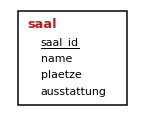

Inhalt der Tabelle `saal`:

<table style="margin-left: 0">
<tr><th style="text-align: right">saal_id</th><th style="text-align: right">name</th><th style="text-align: right">plaetze</th><th style="text-align: right">ausstattung</th></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">Großer Saal</td><td style="text-align: right">220</td><td style="text-align: right">IMAX</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">Blauer Saal</td><td style="text-align: right">140</td><td style="text-align: right">3D</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">Roter Saal</td><td style="text-align: right">90</td><td style="text-align: right">Standard</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">Lounge</td><td style="text-align: right">40</td><td style="text-align: right">Lounge</td></tr>
</table>

*4 Zeilen*

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT name, plaetze FROM saal ORDER BY ausstattung DESC LIMIT 2;
```

In [ ]:
SELECT name, plaetze FROM saal ORDER BY ausstattung DESC LIMIT 2;

## 5. Aggregatfunktionen

#### Zählen, Summe, Durchschnitt, Minimum und Maximum

**Aggregatfunktionen** fassen viele Zeilen zu **einem** Wert zusammen:

| Funktion | Ergebnis |
|---|---|
| `COUNT(*)` | Anzahl der Zeilen |
| `COUNT(spalte)` | Anzahl der Zeilen, in denen die Spalte **nicht** `NULL` ist |
| `COUNT(DISTINCT spalte)` | Anzahl der verschiedenen Werte |
| `SUM(spalte)`, `AVG(spalte)` | Summe, Durchschnitt |
| `MIN(spalte)`, `MAX(spalte)` | kleinster, größter Wert |

Mit `WHERE` werden vorher die Zeilen ausgewählt, die zusammengefasst werden. Den Ergebnisspalten gibt man am besten mit `AS` einen Namen.

In [ ]:
SELECT COUNT(*) AS anzahl, MIN(dauer) AS kuerzester, MAX(dauer) AS laengster, ROUND(AVG(dauer), 1) AS durchschnitt
FROM film;

#### Aufgabe 5.1

Gib aus, wie viele Filme es gibt (Spaltenname `anzahl`).

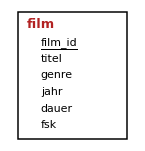

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">21</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(*) AS anzahl FROM film;
```

</details>

#### Aufgabe 5.2

Gib aus, wie viele Kunden eine E-Mail-Adresse haben. Verwende `COUNT(email)`.

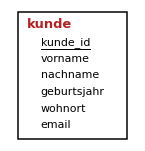

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">mit_email</th></tr>
<tr><td style="text-align: right">16</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(email) AS mit_email FROM kunde;
```

</details>

#### Aufgabe 5.3

Gib die durchschnittliche Dauer aller Filme aus, gerundet auf eine Nachkommastelle.

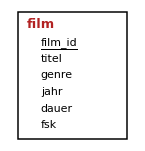

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">durchschnitt</th></tr>
<tr><td style="text-align: right">106.0</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT ROUND(AVG(dauer), 1) AS durchschnitt FROM film;
```

</details>

#### Aufgabe 5.4

Gib die Gesamtzahl der Plätze in allen Sälen aus.

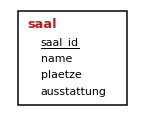

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">plaetze_gesamt</th></tr>
<tr><td style="text-align: right">490</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT SUM(plaetze) AS plaetze_gesamt FROM saal;
```

</details>

#### Aufgabe 5.5

Gib aus, wie viele Vorstellungen am Dienstag, dem 3. November, stattfinden.

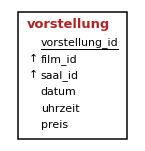

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">7</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(*) AS anzahl FROM vorstellung WHERE datum = '2026-11-03';
```

</details>

#### Aufgabe 5.6

Gib aus, aus wie vielen verschiedenen Orten die Kunden kommen.

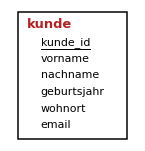

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">orte</th></tr>
<tr><td style="text-align: right">5</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(DISTINCT wohnort) AS orte FROM kunde;
```

</details>

#### Aufgabe 5.7

Gib den Durchschnittspreis der Vorstellungen in Saal 4 aus, gerundet auf zwei Nachkommastellen.

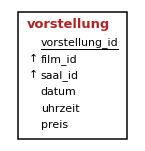

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">durchschnittspreis</th></tr>
<tr><td style="text-align: right">15.0</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT ROUND(AVG(preis), 2) AS durchschnittspreis FROM vorstellung WHERE saal_id = 4;
```

</details>

#### Aufgabe 5.8

Gib aus, wie viele ermäßigte Tickets verkauft wurden. Verwende `SUM()` (die Spalte enthält 1 oder 0).

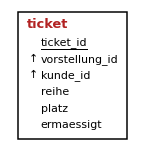

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">ermaessigt</th></tr>
<tr><td style="text-align: right">41</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT SUM(ermaessigt) AS ermaessigt FROM ticket;
```

</details>

#### Aufgabe 5.9

Gib das Geburtsjahr des ältesten und des jüngsten Kunden aus (Spalten `aeltester` und `juengster`).

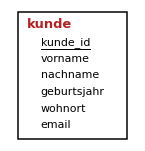

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">aeltester</th><th style="text-align: right">juengster</th></tr>
<tr><td style="text-align: right">1948</td><td style="text-align: right">2012</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT MIN(geburtsjahr) AS aeltester, MAX(geburtsjahr) AS juengster FROM kunde;
```

</details>

#### Aufgabe 5.10

Gib aus, wie viele Filme FSK 16 oder FSK 18 haben.

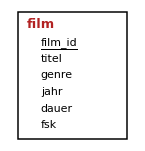

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">5</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(*) AS anzahl FROM film WHERE fsk >= 16;
```

</details>

#### Aufgabe 5.11

Gib aus, wie viele Tickets für die Vorstellung mit der Nummer 18 verkauft wurden.

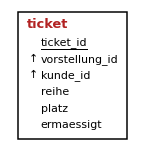

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">6</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(*) AS tickets FROM ticket WHERE vorstellung_id = 18;
```

</details>

#### Aufgabe 5.12

Gib den niedrigsten, den höchsten und den durchschnittlichen Eintrittspreis aus (Durchschnitt auf zwei Stellen gerundet).

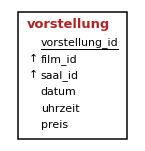

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">min</th><th style="text-align: right">max</th><th style="text-align: right">schnitt</th></tr>
<tr><td style="text-align: right">6.5</td><td style="text-align: right">15.5</td><td style="text-align: right">12.13</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT MIN(preis) AS min, MAX(preis) AS max, ROUND(AVG(preis), 2) AS schnitt FROM vorstellung;
```

</details>

#### Aufgabe 5.13

Gib in einer Zeile aus, wie viele Kunden es gibt (`kunden`), wie viele davon eine E-Mail-Adresse haben (`mit_email`) und aus wie vielen verschiedenen Orten sie kommen (`orte`).

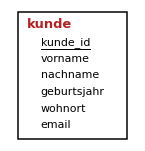

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">kunden</th><th style="text-align: right">mit_email</th><th style="text-align: right">orte</th></tr>
<tr><td style="text-align: right">24</td><td style="text-align: right">16</td><td style="text-align: right">5</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(*) AS kunden, COUNT(email) AS mit_email, COUNT(DISTINCT wohnort) AS orte FROM kunde;
```

</details>

## 6. Gruppieren mit GROUP BY und HAVING

#### `GROUP BY`

`GROUP BY spalte` bildet **Gruppen** aus allen Zeilen mit demselben Wert in dieser Spalte. Aggregatfunktionen werden dann **pro Gruppe** berechnet.
Im `SELECT` sollten nur die Gruppierungs-Spalte und Aggregatfunktionen stehen.

In [ ]:
SELECT genre, COUNT(*) AS anzahl
FROM film
GROUP BY genre
ORDER BY anzahl DESC;

#### `HAVING`

`WHERE` wählt **Zeilen** vor dem Gruppieren aus, `HAVING` wählt **Gruppen** nach dem Gruppieren aus.
In `HAVING` darf man deshalb Aggregatfunktionen verwenden, in `WHERE` nicht.

Hat die Aggregatfunktion im `SELECT` einen Namen bekommen (`COUNT(*) AS anzahl`), kann man in SQLite im `HAVING` diesen Namen verwenden: `HAVING anzahl >= 2`.
Das ist kürzer und besser lesbar. (Nicht jedes Datenbanksystem erlaubt das; in Standard-SQL schreibt man `HAVING COUNT(*) >= 2`.)

Reihenfolge: `SELECT ... FROM ... WHERE ... GROUP BY ... HAVING ... ORDER BY ... LIMIT ...`

In [ ]:
SELECT wohnort, COUNT(*) AS anzahl
FROM kunde
WHERE geburtsjahr < 2000
GROUP BY wohnort
HAVING anzahl >= 2;

#### Aufgabe 6.1

Gib für jedes Genre die Anzahl der Filme aus.

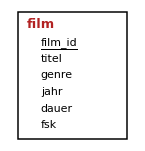

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">Action</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Animation</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Dokumentation</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">3</td></tr>
<tr><td style="text-align: right">Familie</td><td style="text-align: right">1</td></tr>
<tr><td style="text-align: right">Horror</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Komödie</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Krimi</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">3</td></tr>
</table>

*9 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT genre, COUNT(*) AS anzahl FROM film GROUP BY genre;
```

</details>

#### Aufgabe 6.2

Gib für jeden Wohnort die Anzahl der Kunden aus, den Ort mit den meisten Kunden zuerst.

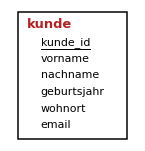

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">wohnort</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">Münster</td><td style="text-align: right">12</td></tr>
<tr><td style="text-align: right">Greven</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Telgte</td><td style="text-align: right">3</td></tr>
<tr><td style="text-align: right">Senden</td><td style="text-align: right">3</td></tr>
<tr><td style="text-align: right">Havixbeck</td><td style="text-align: right">2</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT wohnort, COUNT(*) AS anzahl FROM kunde GROUP BY wohnort ORDER BY anzahl DESC;
```

</details>

#### Aufgabe 6.3

Gib für jedes Genre die durchschnittliche Filmdauer aus, auf ganze Minuten gerundet (`ROUND(..., 0)`), nach Dauer absteigend sortiert.

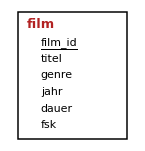

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">dauer</th></tr>
<tr><td style="text-align: right">Action</td><td style="text-align: right">128.0</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">124.0</td></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">116.0</td></tr>
<tr><td style="text-align: right">Krimi</td><td style="text-align: right">111.0</td></tr>
<tr><td style="text-align: right">Komödie</td><td style="text-align: right">99.0</td></tr>
<tr><td style="text-align: right">Horror</td><td style="text-align: right">97.0</td></tr>
<tr><td style="text-align: right">Familie</td><td style="text-align: right">95.0</td></tr>
<tr><td style="text-align: right">Animation</td><td style="text-align: right">91.0</td></tr>
<tr><td style="text-align: right">Dokumentation</td><td style="text-align: right">82.0</td></tr>
</table>

*9 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT genre, ROUND(AVG(dauer), 0) AS dauer FROM film GROUP BY genre ORDER BY dauer DESC;
```

</details>

#### Aufgabe 6.4

Gib für jeden Tag die Anzahl der Vorstellungen aus.

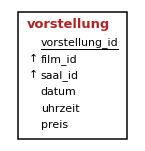

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">2026-11-03</td><td style="text-align: right">7</td></tr>
<tr><td style="text-align: right">2026-11-04</td><td style="text-align: right">8</td></tr>
<tr><td style="text-align: right">2026-11-05</td><td style="text-align: right">7</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">2026-11-07</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">2026-11-08</td><td style="text-align: right">6</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT datum, COUNT(*) AS anzahl FROM vorstellung GROUP BY datum;
```

</details>

#### Aufgabe 6.5

Gib für jeden Saal (Saal-Nummer) die Anzahl der Vorstellungen und den Durchschnittspreis (zwei Stellen) aus.

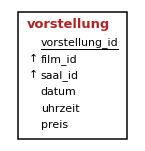

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">saal_id</th><th style="text-align: right">anzahl</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">10</td><td style="text-align: right">11.7</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">10</td><td style="text-align: right">11.4</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">10</td><td style="text-align: right">8.7</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">16</td><td style="text-align: right">15.0</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT saal_id, COUNT(*) AS anzahl, ROUND(AVG(preis), 2) AS preis FROM vorstellung GROUP BY saal_id;
```

</details>

#### Aufgabe 6.6

Gib die Genres aus, zu denen es mehr als 2 Filme gibt, mit der Anzahl.

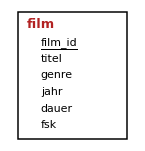

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">3</td></tr>
<tr><td style="text-align: right">Komödie</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">3</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT genre, COUNT(*) AS anzahl FROM film GROUP BY genre HAVING anzahl > 2;
```

</details>

#### Aufgabe 6.7

Gib die Tage aus, an denen mindestens 7 Vorstellungen stattfinden.

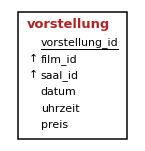

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">2026-11-03</td><td style="text-align: right">7</td></tr>
<tr><td style="text-align: right">2026-11-04</td><td style="text-align: right">8</td></tr>
<tr><td style="text-align: right">2026-11-05</td><td style="text-align: right">7</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT datum, COUNT(*) AS anzahl FROM vorstellung GROUP BY datum HAVING anzahl >= 7;
```

</details>

#### Aufgabe 6.8

Gib die Nummern der Vorstellungen aus, für die genau 6 Tickets verkauft wurden.

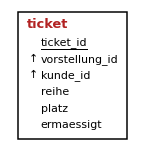

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorstellung_id</th></tr>
<tr><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">7</td></tr>
<tr><td style="text-align: right">18</td></tr>
<tr><td style="text-align: right">36</td></tr>
<tr><td style="text-align: right">37</td></tr>
<tr><td style="text-align: right">44</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorstellung_id FROM ticket GROUP BY vorstellung_id HAVING COUNT(*) = 6;
```

</details>

#### Aufgabe 6.9

Gib für jede Altersfreigabe (FSK) die Anzahl der Filme aus, nach FSK sortiert.

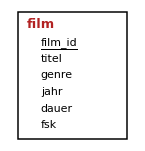

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">fsk</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">0</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">6</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">12</td><td style="text-align: right">8</td></tr>
<tr><td style="text-align: right">16</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">18</td><td style="text-align: right">1</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT fsk, COUNT(*) AS anzahl FROM film GROUP BY fsk ORDER BY fsk;
```

</details>

#### Aufgabe 6.10

Gib für jede Anfangszeit den Durchschnittspreis aus (zwei Stellen).

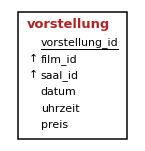

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">uhrzeit</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">11.59</td></tr>
<tr><td style="text-align: right">17:00</td><td style="text-align: right">13.88</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">12.2</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">11.62</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT uhrzeit, ROUND(AVG(preis), 2) AS preis FROM vorstellung GROUP BY uhrzeit;
```

</details>

#### Aufgabe 6.11

Gib für jedes Genre die Anzahl der Filme aus, zähle aber nur Filme ab 2024. Nach Anzahl absteigend, bei Gleichheit nach Genre sortiert.

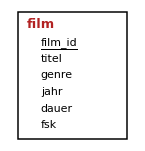

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">Komödie</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">3</td></tr>
<tr><td style="text-align: right">Animation</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Horror</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Action</td><td style="text-align: right">1</td></tr>
<tr><td style="text-align: right">Dokumentation</td><td style="text-align: right">1</td></tr>
<tr><td style="text-align: right">Krimi</td><td style="text-align: right">1</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT genre, COUNT(*) AS anzahl FROM film WHERE jahr >= 2024 GROUP BY genre ORDER BY anzahl DESC, genre;
```

</details>

#### Aufgabe 6.12

Gib für jede Kunden-Nummer die Anzahl der gekauften Tickets aus, aber nur für Kunden mit mehr als 8 Tickets.

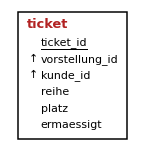

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">kunde_id</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">9</td><td style="text-align: right">10</td></tr>
<tr><td style="text-align: right">18</td><td style="text-align: right">10</td></tr>
</table>

*2 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT kunde_id, COUNT(*) AS tickets FROM ticket GROUP BY kunde_id HAVING tickets > 8;
```

</details>

#### Aufgabe 6.13

Gib die Genres aus, zu denen es mehr als einen Film mit FSK 12 oder höher gibt, mit der Anzahl dieser Filme (`anzahl`), nach Genre sortiert.

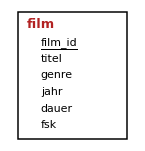

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">Action</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">3</td></tr>
<tr><td style="text-align: right">Horror</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Krimi</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">3</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT genre, COUNT(*) AS anzahl FROM film WHERE fsk >= 12 GROUP BY genre HAVING anzahl > 1 ORDER BY genre;
```

</details>

## 7. Tabellen verbinden mit JOIN

#### Warum verbinden?

In der Tabelle `vorstellung` steht nur die **Nummer** des Films (`film_id`), nicht sein Titel. Den Titel findet man in der Tabelle `film`
in der Zeile mit derselben `film_id`. Mit `JOIN` verbindet man die beiden Tabellen über diese Spalte:

```sql
SELECT ... FROM vorstellung JOIN film ON vorstellung.film_id = film.film_id
```

Hinter `ON` steht die **Verknüpfungsbedingung**: Fremdschlüssel = Primärschlüssel. Kommt ein Spaltenname in beiden Tabellen vor,
schreibt man den Tabellennamen davor: `film.film_id`. Mit **Abkürzungen** (Aliasen) wird es kürzer: `FROM vorstellung v JOIN film f ON v.film_id = f.film_id`.

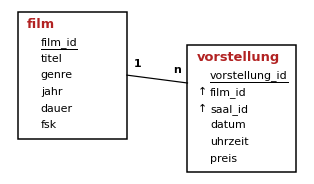

In [ ]:
SELECT v.datum, v.uhrzeit, f.titel
FROM vorstellung v JOIN film f ON v.film_id = f.film_id
WHERE v.datum = '2026-11-02';

#### Die andere Schreibweise

Man kann die Tabellen auch mit Komma aufzählen und die Verknüpfungsbedingung in `WHERE` schreiben. Das Ergebnis ist dasselbe.
**Ohne** Verknüpfungsbedingung wird jede Zeile der einen mit jeder Zeile der anderen Tabelle kombiniert (das **Kreuzprodukt**), das ist fast nie gewollt.

In [ ]:
SELECT v.datum, v.uhrzeit, f.titel
FROM vorstellung v, film f
WHERE v.film_id = f.film_id AND v.datum = '2026-11-02';

#### Aufgabe 7.1

Gib für alle Vorstellungen am 3. November Uhrzeit und Filmtitel aus, nach Uhrzeit sortiert.

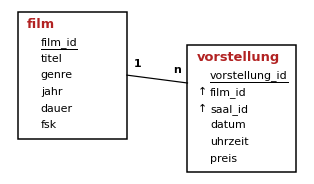

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">uhrzeit</th><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">Planet der Pilze</td></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">Wolkenkratzer</td></tr>
<tr><td style="text-align: right">17:00</td><td style="text-align: right">Fußballfieber</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">Nachtzug nach Wien</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">Planet der Pilze</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">Fußballfieber</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">Schattenspiel</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.uhrzeit, f.titel
FROM vorstellung v JOIN film f ON v.film_id = f.film_id
WHERE v.datum = '2026-11-03'
ORDER BY v.uhrzeit;
```

</details>

#### Aufgabe 7.2

Gib für alle Vorstellungen am 3. November Uhrzeit und Saalname aus, nach Uhrzeit sortiert.

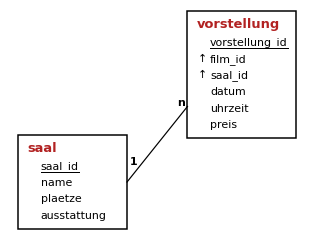

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">uhrzeit</th><th style="text-align: right">name</th></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">Roter Saal</td></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">Lounge</td></tr>
<tr><td style="text-align: right">17:00</td><td style="text-align: right">Lounge</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">Großer Saal</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">Roter Saal</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">Großer Saal</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">Roter Saal</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.uhrzeit, s.name
FROM vorstellung v JOIN saal s ON v.saal_id = s.saal_id
WHERE v.datum = '2026-11-03'
ORDER BY v.uhrzeit;
```

</details>

#### Aufgabe 7.3

Gib Datum und Uhrzeit aller Vorstellungen des Films „Fußballfieber“ aus, nach Datum sortiert.

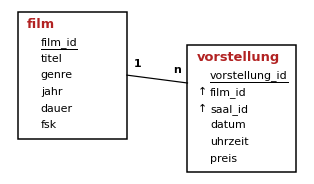

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">2026-11-03</td><td style="text-align: right">17:00</td></tr>
<tr><td style="text-align: right">2026-11-03</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">2026-11-04</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">2026-11-07</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">2026-11-08</td><td style="text-align: right">17:00</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.datum, v.uhrzeit
FROM vorstellung v JOIN film f ON v.film_id = f.film_id
WHERE f.titel = 'Fußballfieber'
ORDER BY v.datum;
```

</details>

#### Aufgabe 7.4

Gib Datum, Uhrzeit und Preis aller Vorstellungen in der „Lounge“ am 5. November aus. Verwende die Schreibweise mit Komma und `WHERE`.

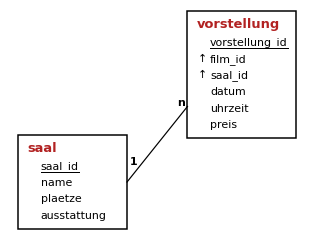

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">2026-11-05</td><td style="text-align: right">14:30</td><td style="text-align: right">14.5</td></tr>
<tr><td style="text-align: right">2026-11-05</td><td style="text-align: right">20:00</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">2026-11-05</td><td style="text-align: right">22:30</td><td style="text-align: right">15.5</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.datum, v.uhrzeit, v.preis
FROM vorstellung v, saal s
WHERE v.saal_id = s.saal_id AND s.name = 'Lounge' AND v.datum = '2026-11-05';
```

</details>

#### Aufgabe 7.5

Gib Titel, Datum und Uhrzeit aller Vorstellungen von Filmen mit FSK 0 aus, nach Datum und Uhrzeit sortiert.

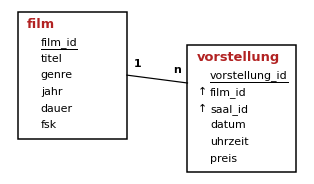

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">20:00</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">20:00</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">Omas großes Abenteuer</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">20:00</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">17:00</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">22:30</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel, v.datum, v.uhrzeit
FROM vorstellung v JOIN film f ON v.film_id = f.film_id
WHERE f.fsk = 0
ORDER BY v.datum, v.uhrzeit;
```

</details>

#### Aufgabe 7.6

Gib Vorname, Nachname, Reihe und Platz aller Kunden mit einem Ticket für die Vorstellung 5 aus, nach Reihe und Platz sortiert.

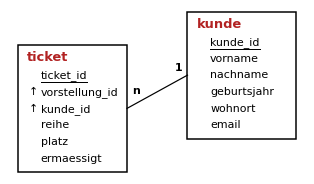

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">reihe</th><th style="text-align: right">platz</th></tr>
<tr><td style="text-align: right">Ella</td><td style="text-align: right">Hofmann</td><td style="text-align: right">2</td><td style="text-align: right">9</td></tr>
<tr><td style="text-align: right">Sophie</td><td style="text-align: right">Meyer</td><td style="text-align: right">2</td><td style="text-align: right">14</td></tr>
<tr><td style="text-align: right">Theo</td><td style="text-align: right">Schmitt</td><td style="text-align: right">3</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Hannah</td><td style="text-align: right">Koch</td><td style="text-align: right">6</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">Elias</td><td style="text-align: right">Richter</td><td style="text-align: right">11</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Emma</td><td style="text-align: right">Fischer</td><td style="text-align: right">11</td><td style="text-align: right">4</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname, t.reihe, t.platz
FROM ticket t JOIN kunde k ON t.kunde_id = k.kunde_id
WHERE t.vorstellung_id = 5
ORDER BY t.reihe, t.platz;
```

</details>

#### Aufgabe 7.7

Gib Vorstellungs-Nummer, Reihe und Platz aller Tickets von Lena Hoffmann aus.

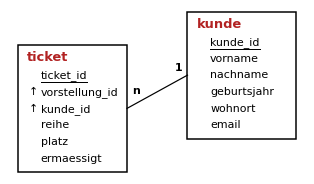

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorstellung_id</th><th style="text-align: right">reihe</th><th style="text-align: right">platz</th></tr>
<tr><td style="text-align: right">7</td><td style="text-align: right">3</td><td style="text-align: right">11</td></tr>
<tr><td style="text-align: right">16</td><td style="text-align: right">2</td><td style="text-align: right">14</td></tr>
<tr><td style="text-align: right">18</td><td style="text-align: right">9</td><td style="text-align: right">9</td></tr>
<tr><td style="text-align: right">30</td><td style="text-align: right">5</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">43</td><td style="text-align: right">2</td><td style="text-align: right">1</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT t.vorstellung_id, t.reihe, t.platz
FROM ticket t JOIN kunde k ON t.kunde_id = k.kunde_id
WHERE k.vorname = 'Lena' AND k.nachname = 'Hoffmann';
```

</details>

#### Aufgabe 7.8

Gib für die Vorstellungen 1 bis 6 die Nummer, die Ausstattung des Saals und den Preis aus.

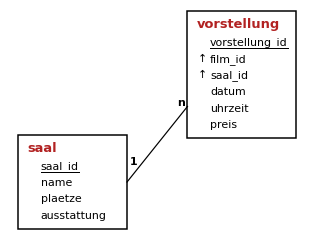

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorstellung_id</th><th style="text-align: right">ausstattung</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">IMAX</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">Standard</td><td style="text-align: right">8.5</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">Lounge</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">Lounge</td><td style="text-align: right">15.5</td></tr>
<tr><td style="text-align: right">5</td><td style="text-align: right">IMAX</td><td style="text-align: right">12.5</td></tr>
<tr><td style="text-align: right">6</td><td style="text-align: right">Lounge</td><td style="text-align: right">15.5</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.vorstellung_id, s.ausstattung, v.preis
FROM vorstellung v JOIN saal s ON v.saal_id = s.saal_id
WHERE v.vorstellung_id <= 6;
```

</details>

#### Aufgabe 7.9

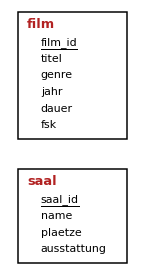

Die Tabelle `film` hat 21 Zeilen, die Tabelle `saal` hat 4 Zeilen.

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT COUNT(*) FROM film, saal;
```

In [ ]:
SELECT COUNT(*) FROM film, saal;

#### Aufgabe 7.10

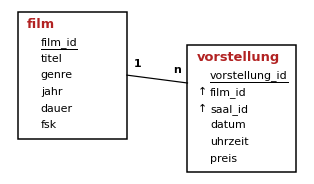

Die Tabelle `vorstellung` hat 46 Zeilen, die Tabelle `film` hat 21 Zeilen. Jede Vorstellung gehört zu genau einem Film.

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT COUNT(*)
FROM vorstellung v JOIN film f ON v.film_id = f.film_id;
```

In [ ]:
SELECT COUNT(*)
FROM vorstellung v JOIN film f ON v.film_id = f.film_id;

## 8. Mehrere Tabellen verbinden

#### Ketten von JOINs

Man kann beliebig viele Tabellen verbinden, indem man mehrere `JOIN ... ON ...` hintereinander schreibt.
Für jede Verbindungslinie im Diagramm braucht man eine Verknüpfungsbedingung. Um von einem Kunden zum Filmtitel zu kommen, geht man
`kunde` → `ticket` → `vorstellung` → `film`.

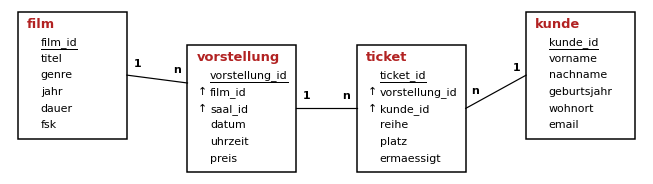

In [ ]:
SELECT k.vorname, k.nachname, f.titel, v.datum
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
WHERE k.nachname = 'Wagner';

#### Aufgabe 8.1

Gib Titel, Datum und Uhrzeit aller Filme aus, die Jonas Becker gesehen hat, nach Datum sortiert.

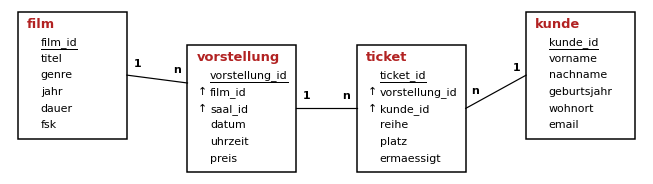

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">2026-11-02</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">Planet der Pilze</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">Funkstille</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">Mission Mondbasis</td><td style="text-align: right">2026-11-04</td><td style="text-align: right">22:30</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel, v.datum, v.uhrzeit
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
WHERE k.vorname = 'Jonas' AND k.nachname = 'Becker'
ORDER BY v.datum;
```

</details>

#### Aufgabe 8.2

Gib Vorname und Nachname aller Kunden aus, die den Film „Mission Mondbasis“ gesehen haben.

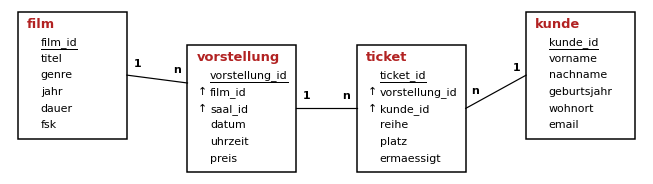

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Luca</td><td style="text-align: right">Neumann</td></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">Becker</td></tr>
<tr><td style="text-align: right">Frieda</td><td style="text-align: right">Lange</td></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td></tr>
<tr><td style="text-align: right">Mia</td><td style="text-align: right">Schulz</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
WHERE f.titel = 'Mission Mondbasis';
```

</details>

#### Aufgabe 8.3

Gib die Titel aller Filme aus, die im „Großen Saal“ laufen, jeden nur einmal und alphabetisch.

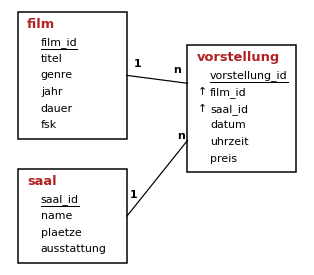

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td></tr>
<tr><td style="text-align: right">Funkstille</td></tr>
<tr><td style="text-align: right">Fußballfieber</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td></tr>
<tr><td style="text-align: right">Omas großes Abenteuer</td></tr>
<tr><td style="text-align: right">Schattenspiel</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT f.titel
FROM film f
JOIN vorstellung v ON v.film_id = f.film_id
JOIN saal s ON v.saal_id = s.saal_id
WHERE s.name = 'Großer Saal'
ORDER BY f.titel;
```

</details>

#### Aufgabe 8.4

Gib Datum, Uhrzeit, Saalname und Filmtitel aller Vorstellungen am 6. November aus, nach Uhrzeit sortiert.

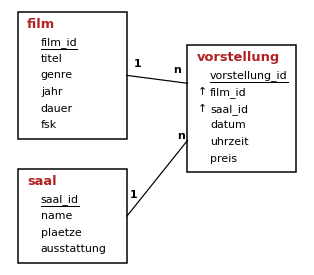

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th><th style="text-align: right">name</th><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td><td style="text-align: right">Großer Saal</td><td style="text-align: right">Die Bienenkönigin</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td><td style="text-align: right">Blauer Saal</td><td style="text-align: right">Galaxis Express</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">17:00</td><td style="text-align: right">Großer Saal</td><td style="text-align: right">Schattenspiel</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">20:00</td><td style="text-align: right">Roter Saal</td><td style="text-align: right">Sommer in Lissabon</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">Blauer Saal</td><td style="text-align: right">Der Leuchtturm am Ende der Welt</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">Roter Saal</td><td style="text-align: right">Planet der Pilze</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.datum, v.uhrzeit, s.name, f.titel
FROM vorstellung v
JOIN saal s ON v.saal_id = s.saal_id
JOIN film f ON v.film_id = f.film_id
WHERE v.datum = '2026-11-06'
ORDER BY v.uhrzeit;
```

</details>

#### Aufgabe 8.5

Gib Vorname, Nachname und Filmtitel aller Tickets von Kunden aus Havixbeck aus, nach Nachname sortiert.

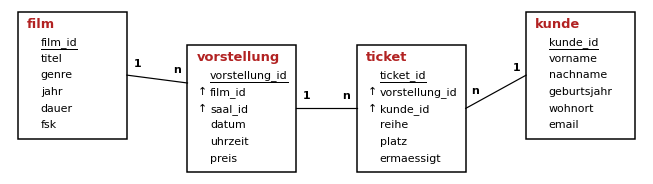

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Der Leuchtturm am Ende der Welt</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Fußballfieber</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Schattenspiel</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Funkstille</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Nachtzug nach Wien</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Der Leuchtturm am Ende der Welt</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">Nachtzug nach Wien</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">Planet der Pilze</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">Nachtzug nach Wien</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">Kettenreaktion</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">Sommer in Lissabon</td></tr>
</table>

*11 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname, f.titel
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
WHERE k.wohnort = 'Havixbeck'
ORDER BY k.nachname;
```

</details>

#### Aufgabe 8.6

Gib Vorname und Nachname aller Kunden aus, die einen Horrorfilm gesehen haben, jeden nur einmal und nach Nachname sortiert.

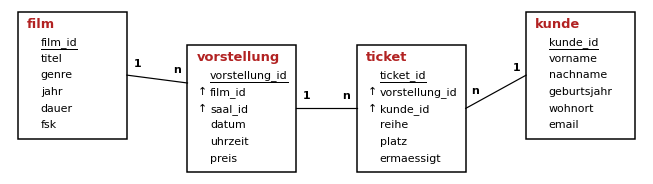

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td></tr>
<tr><td style="text-align: right">Sophie</td><td style="text-align: right">Meyer</td></tr>
<tr><td style="text-align: right">Marie</td><td style="text-align: right">Schröder</td></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT k.vorname, k.nachname
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
WHERE f.genre = 'Horror'
ORDER BY k.nachname;
```

</details>

#### Aufgabe 8.7

Gib für alle Tickets der Vorstellungen am 8. November um 20:00 Uhr den Saalnamen, den Filmtitel, den Nachnamen des Kunden sowie Reihe und Platz aus,
nach Reihe und Platz sortiert.

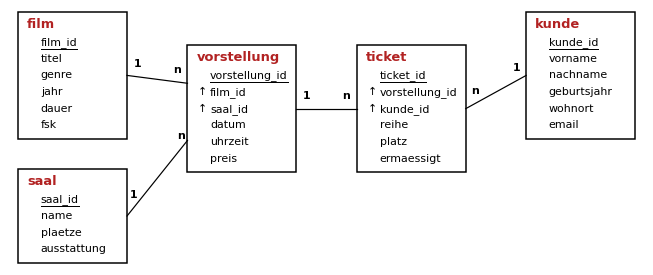

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th><th style="text-align: right">titel</th><th style="text-align: right">nachname</th><th style="text-align: right">reihe</th><th style="text-align: right">platz</th></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Schwarz</td><td style="text-align: right">1</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Schulz</td><td style="text-align: right">1</td><td style="text-align: right">10</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Braun</td><td style="text-align: right">1</td><td style="text-align: right">11</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Koch</td><td style="text-align: right">1</td><td style="text-align: right">15</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Meyer</td><td style="text-align: right">1</td><td style="text-align: right">18</td></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">Wolf</td><td style="text-align: right">1</td><td style="text-align: right">20</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT s.name, f.titel, k.nachname, t.reihe, t.platz
FROM ticket t
JOIN kunde k ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
JOIN saal s ON v.saal_id = s.saal_id
WHERE v.datum = '2026-11-08' AND v.uhrzeit = '20:00'
ORDER BY t.reihe, t.platz;
```

</details>

#### Aufgabe 8.8

Gib die Wohnorte aller Kunden aus, die im „Roten Saal“ waren, jeden nur einmal und alphabetisch.

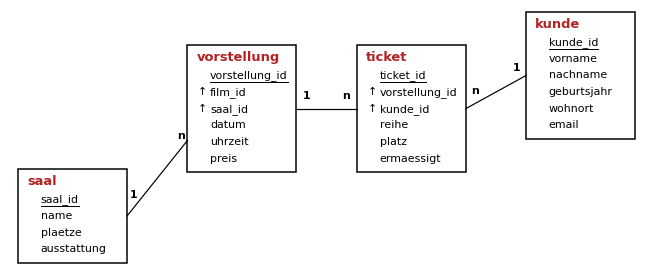

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">wohnort</th></tr>
<tr><td style="text-align: right">Greven</td></tr>
<tr><td style="text-align: right">Havixbeck</td></tr>
<tr><td style="text-align: right">Münster</td></tr>
<tr><td style="text-align: right">Senden</td></tr>
<tr><td style="text-align: right">Telgte</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT k.wohnort
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN saal s ON v.saal_id = s.saal_id
WHERE s.name = 'Roter Saal'
ORDER BY k.wohnort;
```

</details>

## 9. JOIN und GROUP BY

#### Verbinden und zusammenfassen

`JOIN` und `GROUP BY` lassen sich kombinieren: zuerst verbinden, dann gruppieren. So zählt man zum Beispiel die Tickets **pro Film**.
Gruppiert man nach dem Primärschlüssel (`f.film_id`), darf man auch die anderen Spalten dieser Tabelle (z. B. `f.titel`) ausgeben.

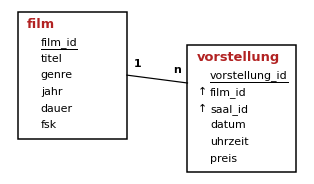

In [ ]:
SELECT f.titel, COUNT(*) AS vorstellungen
FROM film f JOIN vorstellung v ON v.film_id = f.film_id
GROUP BY f.film_id
ORDER BY vorstellungen DESC
LIMIT 3;

#### Aufgabe 9.1

Gib für jeden Film die Anzahl der Vorstellungen aus, nach Anzahl absteigend und bei Gleichheit nach Titel sortiert. Nur die ersten 6.

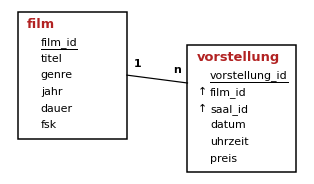

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">vorstellungen</th></tr>
<tr><td style="text-align: right">Fußballfieber</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Planet der Pilze</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">3</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel, COUNT(*) AS vorstellungen
FROM film f JOIN vorstellung v ON v.film_id = f.film_id
GROUP BY f.film_id
ORDER BY vorstellungen DESC, f.titel
LIMIT 6;
```

</details>

#### Aufgabe 9.2

Gib die 5 Filme mit den meisten verkauften Tickets aus (Titel und Anzahl), bei Gleichheit nach Titel sortiert.

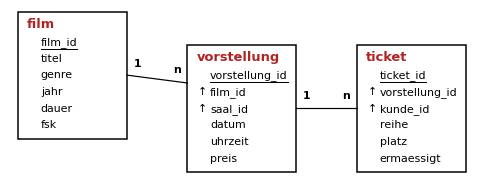

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">21</td></tr>
<tr><td style="text-align: right">Fußballfieber</td><td style="text-align: right">20</td></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td><td style="text-align: right">15</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td><td style="text-align: right">11</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">9</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel, COUNT(*) AS tickets
FROM ticket t
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
GROUP BY f.film_id
ORDER BY tickets DESC, f.titel
LIMIT 5;
```

</details>

#### Aufgabe 9.3

Gib die 5 Filme mit dem höchsten Umsatz aus: die Summe der Eintrittspreise aller verkauften Tickets (ohne Ermäßigung). Spalte `umsatz`.

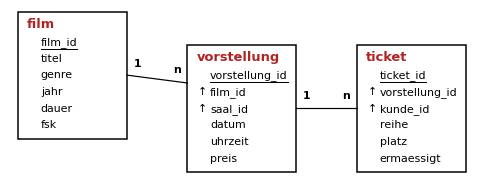

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">umsatz</th></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">292.5</td></tr>
<tr><td style="text-align: right">Fußballfieber</td><td style="text-align: right">247.0</td></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td><td style="text-align: right">190.5</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td><td style="text-align: right">140.5</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">115.5</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel, SUM(v.preis) AS umsatz
FROM ticket t
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
GROUP BY f.film_id
ORDER BY umsatz DESC
LIMIT 5;
```

</details>

#### Aufgabe 9.4

Gib für jeden Saal (Name) die Anzahl der verkauften Tickets aus, den Saal mit den meisten zuerst.

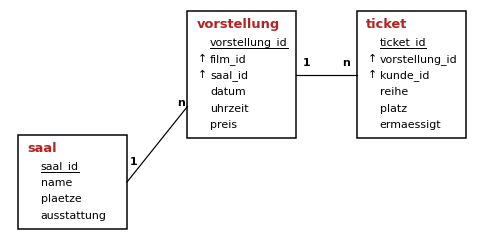

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">55</td></tr>
<tr><td style="text-align: right">Blauer Saal</td><td style="text-align: right">30</td></tr>
<tr><td style="text-align: right">Roter Saal</td><td style="text-align: right">24</td></tr>
<tr><td style="text-align: right">Großer Saal</td><td style="text-align: right">21</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT s.name, COUNT(*) AS tickets
FROM ticket t
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN saal s ON v.saal_id = s.saal_id
GROUP BY s.saal_id
ORDER BY tickets DESC;
```

</details>

#### Aufgabe 9.5

Gib Vorname, Nachname und Anzahl der Tickets der 5 Kunden mit den meisten Tickets aus, bei Gleichheit nach Nachname sortiert.

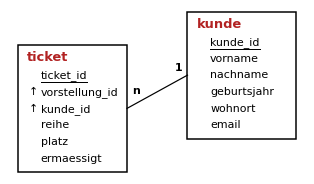

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">Hannah</td><td style="text-align: right">Koch</td><td style="text-align: right">10</td></tr>
<tr><td style="text-align: right">Leon</td><td style="text-align: right">Krüger</td><td style="text-align: right">10</td></tr>
<tr><td style="text-align: right">Ella</td><td style="text-align: right">Hofmann</td><td style="text-align: right">8</td></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td><td style="text-align: right">8</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td><td style="text-align: right">7</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname, COUNT(*) AS tickets
FROM kunde k JOIN ticket t ON t.kunde_id = k.kunde_id
GROUP BY k.kunde_id
ORDER BY tickets DESC, k.nachname
LIMIT 5;
```

</details>

#### Aufgabe 9.6

Gib für jeden Wohnort die Anzahl der verkauften Tickets aus, nach Anzahl absteigend sortiert.

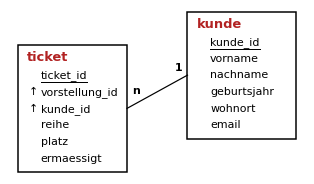

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">wohnort</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">Münster</td><td style="text-align: right">63</td></tr>
<tr><td style="text-align: right">Greven</td><td style="text-align: right">23</td></tr>
<tr><td style="text-align: right">Telgte</td><td style="text-align: right">20</td></tr>
<tr><td style="text-align: right">Senden</td><td style="text-align: right">13</td></tr>
<tr><td style="text-align: right">Havixbeck</td><td style="text-align: right">11</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.wohnort, COUNT(*) AS tickets
FROM kunde k JOIN ticket t ON t.kunde_id = k.kunde_id
GROUP BY k.wohnort
ORDER BY tickets DESC;
```

</details>

#### Aufgabe 9.7

Gib für jedes Genre die Anzahl der verkauften Tickets aus, aber nur Genres mit mindestens 15 Tickets.

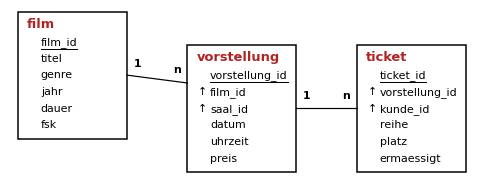

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">23</td></tr>
<tr><td style="text-align: right">Komödie</td><td style="text-align: right">31</td></tr>
<tr><td style="text-align: right">Krimi</td><td style="text-align: right">22</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">19</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.genre, COUNT(*) AS tickets
FROM ticket t
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
GROUP BY f.genre
HAVING tickets >= 15;
```

</details>

#### Aufgabe 9.8

Gib für jeden Tag die Einnahmen aus allen verkauften Tickets aus (Summe der Preise, ohne Ermäßigung).

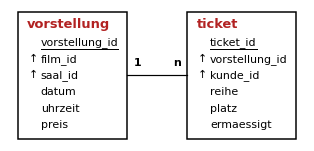

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">einnahmen</th></tr>
<tr><td style="text-align: right">2026-11-02</td><td style="text-align: right">345.5</td></tr>
<tr><td style="text-align: right">2026-11-03</td><td style="text-align: right">158.0</td></tr>
<tr><td style="text-align: right">2026-11-04</td><td style="text-align: right">371.0</td></tr>
<tr><td style="text-align: right">2026-11-05</td><td style="text-align: right">153.5</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">117.5</td></tr>
<tr><td style="text-align: right">2026-11-07</td><td style="text-align: right">246.0</td></tr>
<tr><td style="text-align: right">2026-11-08</td><td style="text-align: right">237.5</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.datum, SUM(v.preis) AS einnahmen
FROM ticket t JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
GROUP BY v.datum;
```

</details>

#### Aufgabe 9.9

Betrachte nur ermäßigte Tickets (`ermaessigt = 1`). Gib Vorname, Nachname und die Summe der Preise dieser Tickets (Spalte `summe`) für alle Kunden aus, bei denen die Summe über 20 Euro liegt.

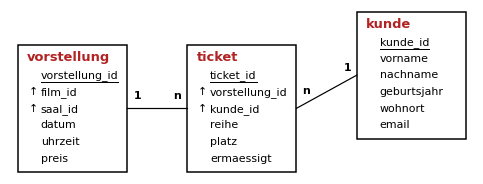

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">summe</th></tr>
<tr><td style="text-align: right">Lena</td><td style="text-align: right">Hoffmann</td><td style="text-align: right">60.5</td></tr>
<tr><td style="text-align: right">Mia</td><td style="text-align: right">Schulz</td><td style="text-align: right">71.5</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">49.0</td></tr>
<tr><td style="text-align: right">Finn</td><td style="text-align: right">Wolf</td><td style="text-align: right">78.0</td></tr>
<tr><td style="text-align: right">Marie</td><td style="text-align: right">Schröder</td><td style="text-align: right">60.5</td></tr>
<tr><td style="text-align: right">Felix</td><td style="text-align: right">Zimmermann</td><td style="text-align: right">76.0</td></tr>
<tr><td style="text-align: right">Ella</td><td style="text-align: right">Hofmann</td><td style="text-align: right">92.0</td></tr>
<tr><td style="text-align: right">Anton</td><td style="text-align: right">Hartmann</td><td style="text-align: right">22.0</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname, SUM(v.preis) AS summe
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
WHERE t.ermaessigt = 1
GROUP BY k.kunde_id
HAVING summe > 20;
```

</details>

## 10. LEFT JOIN

#### Zeilen ohne Partner

`JOIN` (genauer `INNER JOIN`) gibt nur Zeilen aus, die in **beiden** Tabellen einen Partner haben. Ein Film ohne Vorstellung fehlt also im Ergebnis.

`LEFT JOIN` gibt **alle** Zeilen der linken Tabelle aus. Hat eine Zeile keinen Partner, stehen in den Spalten der rechten Tabelle `NULL`-Werte.
Damit findet man Zeilen **ohne** Partner (`WHERE rechts.spalte IS NULL`) oder zählt auch Nullen mit (`COUNT(rechts.spalte)`).

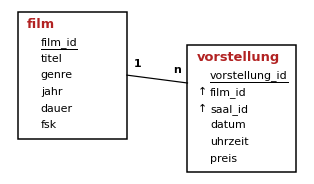

In [ ]:
SELECT f.titel, COUNT(v.vorstellung_id) AS vorstellungen
FROM film f LEFT JOIN vorstellung v ON v.film_id = f.film_id
GROUP BY f.film_id
ORDER BY vorstellungen
LIMIT 6;

#### Aufgabe 10.1

Gib die Titel aller Filme aus, für die es **keine** Vorstellung gibt.

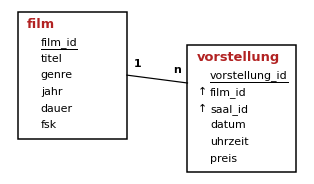

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Robo-Ritter</td></tr>
<tr><td style="text-align: right">Das Geheimnis der alten Mühle</td></tr>
<tr><td style="text-align: right">Ein Koffer voller Träume</td></tr>
<tr><td style="text-align: right">Zeitreise für Anfänger</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel
FROM film f LEFT JOIN vorstellung v ON v.film_id = f.film_id
WHERE v.vorstellung_id IS NULL;
```

</details>

#### Aufgabe 10.2

Gib Vorname und Nachname aller Kunden aus, die **kein** Ticket gekauft haben.

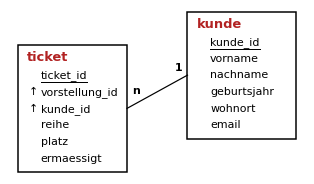

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Lina</td><td style="text-align: right">Werner</td></tr>
<tr><td style="text-align: right">Karl</td><td style="text-align: right">Krause</td></tr>
</table>

*2 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname
FROM kunde k LEFT JOIN ticket t ON t.kunde_id = k.kunde_id
WHERE t.ticket_id IS NULL;
```

</details>

#### Aufgabe 10.3

Gib für die 5 Kunden mit den wenigsten Tickets Vorname, Nachname und Anzahl (auch 0) aus, bei Gleichheit nach Nachname sortiert.

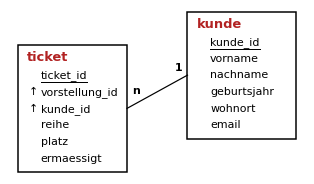

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">Karl</td><td style="text-align: right">Krause</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">Lina</td><td style="text-align: right">Werner</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">Anton</td><td style="text-align: right">Hartmann</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">Becker</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td><td style="text-align: right">4</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname, COUNT(t.ticket_id) AS tickets
FROM kunde k LEFT JOIN ticket t ON t.kunde_id = k.kunde_id
GROUP BY k.kunde_id
ORDER BY tickets, k.nachname
LIMIT 5;
```

</details>

#### Aufgabe 10.4

Gib Nummer, Datum und Uhrzeit aller Vorstellungen aus, für die kein einziges Ticket verkauft wurde.

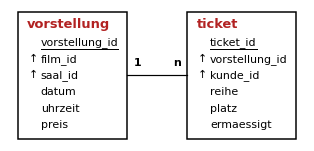

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorstellung_id</th><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th></tr>
<tr><td style="text-align: right">13</td><td style="text-align: right">2026-11-03</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">22</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">26</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">28</td><td style="text-align: right">2026-11-05</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">29</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">34</td><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td></tr>
<tr><td style="text-align: right">35</td><td style="text-align: right">2026-11-07</td><td style="text-align: right">14:30</td></tr>
<tr><td style="text-align: right">45</td><td style="text-align: right">2026-11-08</td><td style="text-align: right">22:30</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.vorstellung_id, v.datum, v.uhrzeit
FROM vorstellung v LEFT JOIN ticket t ON t.vorstellung_id = v.vorstellung_id
WHERE t.ticket_id IS NULL;
```

</details>

#### Aufgabe 10.5

Gib für jedes Genre die Anzahl der Vorstellungen aus, auch wenn sie 0 ist, nach Genre sortiert.

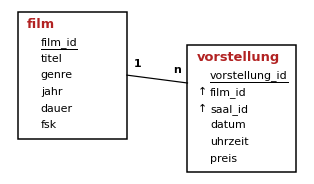

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">vorstellungen</th></tr>
<tr><td style="text-align: right">Action</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Animation</td><td style="text-align: right">2</td></tr>
<tr><td style="text-align: right">Dokumentation</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">7</td></tr>
<tr><td style="text-align: right">Familie</td><td style="text-align: right">0</td></tr>
<tr><td style="text-align: right">Horror</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Komödie</td><td style="text-align: right">11</td></tr>
<tr><td style="text-align: right">Krimi</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">7</td></tr>
</table>

*9 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.genre, COUNT(v.vorstellung_id) AS vorstellungen
FROM film f LEFT JOIN vorstellung v ON v.film_id = f.film_id
GROUP BY f.genre
ORDER BY f.genre;
```

</details>

#### Aufgabe 10.6

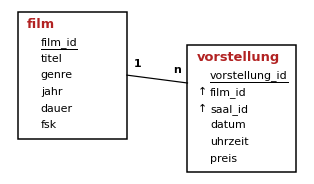

Die Tabelle `vorstellung` hat 46 Zeilen, die Tabelle `film` hat 21 Zeilen. 4 der Filme haben keine Vorstellung.

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT COUNT(*)
FROM film f LEFT JOIN vorstellung v ON v.film_id = f.film_id;
```

In [ ]:
SELECT COUNT(*)
FROM film f LEFT JOIN vorstellung v ON v.film_id = f.film_id;

## 11. Unterabfragen

#### Abfragen in Abfragen

Eine **Unterabfrage** ist eine `SELECT`-Anweisung in Klammern innerhalb einer anderen Anweisung.

- Liefert sie **einen** Wert, kann man damit vergleichen: `WHERE dauer > (SELECT AVG(dauer) FROM film)`.
- Liefert sie eine **Spalte** mit mehreren Werten, prüft man mit `IN` bzw. `NOT IN`, ob ein Wert darin vorkommt.

Erst wird die Unterabfrage ausgewertet, dann die äußere Abfrage.

In [ ]:
SELECT titel, dauer
FROM film
WHERE dauer > (SELECT AVG(dauer) FROM film)
ORDER BY dauer DESC;

#### Aufgabe 11.1

Gib Titel und Dauer aller Filme aus, die kürzer als der Durchschnitt sind, nach Dauer sortiert.

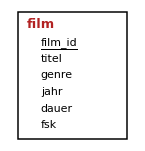

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">dauer</th></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td><td style="text-align: right">78</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">85</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">89</td></tr>
<tr><td style="text-align: right">Robo-Ritter</td><td style="text-align: right">92</td></tr>
<tr><td style="text-align: right">Fußballfieber</td><td style="text-align: right">93</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td><td style="text-align: right">94</td></tr>
<tr><td style="text-align: right">Das Geheimnis der alten Mühle</td><td style="text-align: right">95</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td><td style="text-align: right">97</td></tr>
<tr><td style="text-align: right">Schattenspiel</td><td style="text-align: right">99</td></tr>
<tr><td style="text-align: right">Omas großes Abenteuer</td><td style="text-align: right">101</td></tr>
<tr><td style="text-align: right">Die letzte Spur</td><td style="text-align: right">104</td></tr>
<tr><td style="text-align: right">Zeitreise für Anfänger</td><td style="text-align: right">105</td></tr>
</table>

*12 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, dauer
FROM film
WHERE dauer < (SELECT AVG(dauer) FROM film)
ORDER BY dauer;
```

</details>

#### Aufgabe 11.2

Gib Titel und Dauer des längsten Films aus. Verwende eine Unterabfrage mit `MAX()`.

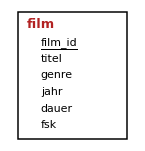

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">dauer</th></tr>
<tr><td style="text-align: right">Mission Mondbasis</td><td style="text-align: right">135</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, dauer FROM film WHERE dauer = (SELECT MAX(dauer) FROM film);
```

</details>

#### Aufgabe 11.3

Gib Vorname, Nachname und Geburtsjahr des ältesten Kunden aus.

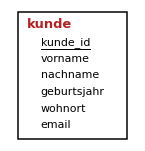

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">geburtsjahr</th></tr>
<tr><td style="text-align: right">Karl</td><td style="text-align: right">Krause</td><td style="text-align: right">1948</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname, geburtsjahr FROM kunde WHERE geburtsjahr = (SELECT MIN(geburtsjahr) FROM kunde);
```

</details>

#### Aufgabe 11.4

Gib die Titel aller Filme aus, die in der „Lounge“ laufen. Verwende zwei verschachtelte Unterabfragen mit `IN` und `=` (ohne JOIN).

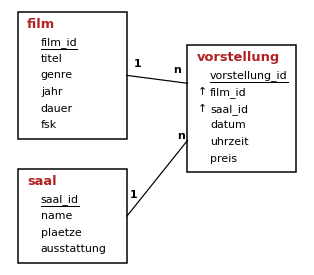

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Der Leuchtturm am Ende der Welt</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td></tr>
<tr><td style="text-align: right">Sommer in Lissabon</td></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td></tr>
<tr><td style="text-align: right">Wolkenkratzer</td></tr>
<tr><td style="text-align: right">Planet der Pilze</td></tr>
<tr><td style="text-align: right">Schattenspiel</td></tr>
<tr><td style="text-align: right">Die Bienenkönigin</td></tr>
<tr><td style="text-align: right">Mission Mondbasis</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td></tr>
<tr><td style="text-align: right">Fußballfieber</td></tr>
</table>

*12 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel
FROM film
WHERE film_id IN (SELECT film_id FROM vorstellung
                  WHERE saal_id = (SELECT saal_id FROM saal WHERE name = 'Lounge'));
```

</details>

#### Aufgabe 11.5

Gib Vorname und Nachname aller Kunden aus, die kein Ticket gekauft haben. Verwende diesmal `NOT IN`.

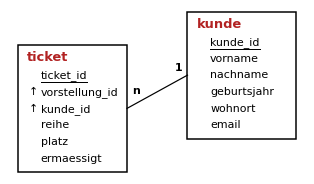

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Lina</td><td style="text-align: right">Werner</td></tr>
<tr><td style="text-align: right">Karl</td><td style="text-align: right">Krause</td></tr>
</table>

*2 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname FROM kunde WHERE kunde_id NOT IN (SELECT kunde_id FROM ticket);
```

</details>

#### Aufgabe 11.6

Gib Datum, Uhrzeit und Preis aller Vorstellungen am 6. November aus, deren Preis unter dem Durchschnittspreis aller Vorstellungen liegt.

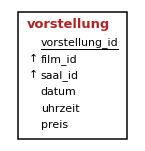

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">datum</th><th style="text-align: right">uhrzeit</th><th style="text-align: right">preis</th></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">14:30</td><td style="text-align: right">10.5</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">20:00</td><td style="text-align: right">9.5</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">11.5</td></tr>
<tr><td style="text-align: right">2026-11-06</td><td style="text-align: right">22:30</td><td style="text-align: right">9.5</td></tr>
</table>

*5 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT datum, uhrzeit, preis
FROM vorstellung
WHERE datum = '2026-11-06' AND preis < (SELECT AVG(preis) FROM vorstellung);
```

</details>

#### Aufgabe 11.7

Gib Vorname und Nachname aller Kunden aus, die älter sind als der Durchschnitt aller Kunden, nach Geburtsjahr sortiert.

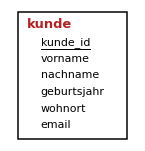

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Karl</td><td style="text-align: right">Krause</td></tr>
<tr><td style="text-align: right">Marie</td><td style="text-align: right">Schröder</td></tr>
<tr><td style="text-align: right">Anton</td><td style="text-align: right">Hartmann</td></tr>
<tr><td style="text-align: right">Hannah</td><td style="text-align: right">Koch</td></tr>
<tr><td style="text-align: right">Lina</td><td style="text-align: right">Werner</td></tr>
<tr><td style="text-align: right">Paul</td><td style="text-align: right">Wagner</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td></tr>
<tr><td style="text-align: right">Emma</td><td style="text-align: right">Fischer</td></tr>
<tr><td style="text-align: right">Clara</td><td style="text-align: right">Schwarz</td></tr>
<tr><td style="text-align: right">Sophie</td><td style="text-align: right">Meyer</td></tr>
</table>

*10 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, nachname
FROM kunde
WHERE geburtsjahr < (SELECT AVG(geburtsjahr) FROM kunde)
ORDER BY geburtsjahr;
```

</details>

#### Aufgabe 11.8

Gib die Titel aller Filme aus dem Genre des Films „Kettenreaktion“ aus (ohne „Kettenreaktion“ selbst).

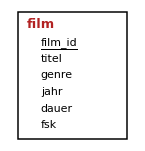

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th></tr>
<tr><td style="text-align: right">Wolkenkratzer</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel
FROM film
WHERE genre = (SELECT genre FROM film WHERE titel = 'Kettenreaktion') AND titel <> 'Kettenreaktion';
```

</details>

#### Aufgabe 11.9

Gib aus, wie viele Filme keine einzige Vorstellung haben (`ohne_vorstellung`). Verwende eine Unterabfrage mit `NOT IN`.

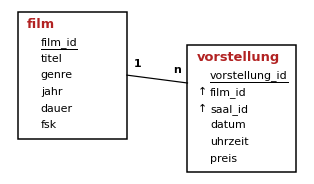

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">ohne_vorstellung</th></tr>
<tr><td style="text-align: right">4</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(*) AS ohne_vorstellung FROM film WHERE film_id NOT IN (SELECT film_id FROM vorstellung);
```

</details>

## 12. Funktionen und CASE

#### Text- und Datumsfunktionen

| Funktion | Ergebnis |
|---|---|
| `UPPER(t)`, `LOWER(t)` | Text in Groß- bzw. Kleinbuchstaben (nur ohne Umlaute zuverlässig) |
| `LENGTH(t)` | Anzahl der Zeichen |
| `SUBSTR(t, start, anzahl)` | Teil des Textes ab Position `start` (die erste Position ist 1) |
| `REPLACE(t, alt, neu)` | ersetzt Textstellen |
| `strftime('%d.%m.%Y', datum)` | Datum in einer anderen Form, hier `02.11.2026` |
| `strftime('%w', datum)` | Wochentag als Text: `'0'` Sonntag, `'1'` Montag, ..., `'6'` Samstag |

In [ ]:
SELECT titel, LENGTH(titel) AS laenge, SUBSTR(titel, 1, 5) AS anfang
FROM film
WHERE genre = 'Animation';

#### `CASE`

Mit `CASE` berechnet man je nach Bedingung einen anderen Wert, ähnlich wie `if` / `elif` / `else`:

```sql
CASE WHEN bedingung1 THEN wert1
     WHEN bedingung2 THEN wert2
     ELSE wert3 END
```

Die Bedingungen werden der Reihe nach geprüft, der erste passende Wert wird genommen.

In [ ]:
SELECT titel, fsk,
       CASE WHEN fsk = 0 THEN 'alle'
            WHEN fsk <= 12 THEN 'Kinder und Jugendliche'
            ELSE 'Erwachsene' END AS zielgruppe
FROM film
WHERE genre = 'Komödie';

#### Aufgabe 12.1

Gib für alle Komödien den Titel in Großbuchstaben (Spalte `gross`) und die Anzahl der Zeichen des Titels (Spalte `zeichen`) aus.

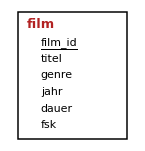

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">gross</th><th style="text-align: right">zeichen</th></tr>
<tr><td style="text-align: right">SOMMER IN LISSABON</td><td style="text-align: right">18</td></tr>
<tr><td style="text-align: right">OMAS GROßES ABENTEUER</td><td style="text-align: right">21</td></tr>
<tr><td style="text-align: right">FUßBALLFIEBER</td><td style="text-align: right">13</td></tr>
<tr><td style="text-align: right">ZEITREISE FüR ANFäNGER</td><td style="text-align: right">22</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT UPPER(titel) AS gross, LENGTH(titel) AS zeichen FROM film WHERE genre = 'Komödie';
```

</details>

#### Aufgabe 12.2

Gib für alle Kunden aus Telgte den abgekürzten Namen aus, z. B. `L. Klein` (Spalte `name`).

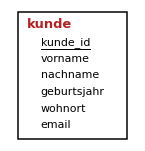

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th></tr>
<tr><td style="text-align: right">P. Wagner</td></tr>
<tr><td style="text-align: right">L. Klein</td></tr>
<tr><td style="text-align: right">E. Hofmann</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT SUBSTR(vorname, 1, 1) || '. ' || nachname AS name FROM kunde WHERE wohnort = 'Telgte';
```

</details>

#### Aufgabe 12.3

Gib alle Spieltage im deutschen Format (z. B. `02.11.2026`) aus, jeden nur einmal (Spalte `tag`).

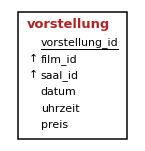

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">tag</th></tr>
<tr><td style="text-align: right">02.11.2026</td></tr>
<tr><td style="text-align: right">03.11.2026</td></tr>
<tr><td style="text-align: right">04.11.2026</td></tr>
<tr><td style="text-align: right">05.11.2026</td></tr>
<tr><td style="text-align: right">06.11.2026</td></tr>
<tr><td style="text-align: right">07.11.2026</td></tr>
<tr><td style="text-align: right">08.11.2026</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT strftime('%d.%m.%Y', datum) AS tag FROM vorstellung;
```

</details>

#### Aufgabe 12.4

Gib für alle Kunden aus Greven Vorname und Alter im Jahr 2026 aus, die jüngsten zuerst.

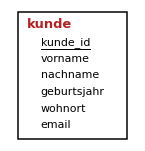

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">alter_2026</th></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">18</td></tr>
<tr><td style="text-align: right">Frieda</td><td style="text-align: right">31</td></tr>
<tr><td style="text-align: right">Clara</td><td style="text-align: right">39</td></tr>
<tr><td style="text-align: right">Hannah</td><td style="text-align: right">58</td></tr>
</table>

*4 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, 2026 - geburtsjahr AS alter_2026 FROM kunde WHERE wohnort = 'Greven' ORDER BY alter_2026;
```

</details>

#### Aufgabe 12.5

Gib für alle Filme aus 2025 den Titel, die Dauer und eine Spalte `laenge` aus: `kurz` unter 100 Minuten, `mittel` bis 120 Minuten, sonst `lang`.
Nach Dauer sortiert.

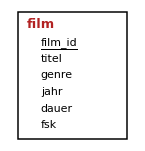

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">dauer</th><th style="text-align: right">laenge</th></tr>
<tr><td style="text-align: right">Tiefsee – Das unbekannte Blau</td><td style="text-align: right">85</td><td style="text-align: right">kurz</td></tr>
<tr><td style="text-align: right">Pinguine auf Abwegen</td><td style="text-align: right">89</td><td style="text-align: right">kurz</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td><td style="text-align: right">94</td><td style="text-align: right">kurz</td></tr>
<tr><td style="text-align: right">Omas großes Abenteuer</td><td style="text-align: right">101</td><td style="text-align: right">mittel</td></tr>
<tr><td style="text-align: right">Zeitreise für Anfänger</td><td style="text-align: right">105</td><td style="text-align: right">mittel</td></tr>
<tr><td style="text-align: right">Funkstille</td><td style="text-align: right">116</td><td style="text-align: right">mittel</td></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">118</td><td style="text-align: right">mittel</td></tr>
<tr><td style="text-align: right">Galaxis Express</td><td style="text-align: right">128</td><td style="text-align: right">lang</td></tr>
<tr><td style="text-align: right">Kettenreaktion</td><td style="text-align: right">131</td><td style="text-align: right">lang</td></tr>
<tr><td style="text-align: right">Mission Mondbasis</td><td style="text-align: right">135</td><td style="text-align: right">lang</td></tr>
</table>

*10 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT titel, dauer,
       CASE WHEN dauer < 100 THEN 'kurz'
            WHEN dauer <= 120 THEN 'mittel'
            ELSE 'lang' END AS laenge
FROM film
WHERE jahr = 2025
ORDER BY dauer;
```

</details>

#### Aufgabe 12.6

Gib aus, wie viele Filme kurz, mittel und lang sind (Einteilung wie in der vorigen Aufgabe). Gruppiere nach dem `CASE`-Ausdruck.

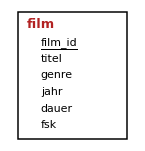

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">laenge</th><th style="text-align: right">anzahl</th></tr>
<tr><td style="text-align: right">kurz</td><td style="text-align: right">9</td></tr>
<tr><td style="text-align: right">lang</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">mittel</td><td style="text-align: right">7</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT CASE WHEN dauer < 100 THEN 'kurz'
            WHEN dauer <= 120 THEN 'mittel'
            ELSE 'lang' END AS laenge,
       COUNT(*) AS anzahl
FROM film
GROUP BY laenge;
```

</details>

#### Aufgabe 12.7

Berechne die tatsächlichen Gesamteinnahmen: Ermäßigte Tickets kosten 80 % des Preises. Verwende `CASE` in `SUM()` und runde auf zwei Nachkommastellen.

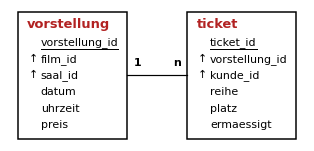

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">einnahmen</th></tr>
<tr><td style="text-align: right">1527.1</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT ROUND(SUM(CASE WHEN t.ermaessigt = 1 THEN v.preis * 0.8 ELSE v.preis END), 2) AS einnahmen
FROM ticket t JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id;
```

</details>

#### Aufgabe 12.8

Gib aus, wie viele Vorstellungen am Wochenende (Samstag und Sonntag) stattfinden. Verwende `strftime('%w', datum)`.

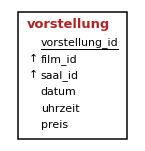

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">wochenende</th></tr>
<tr><td style="text-align: right">12</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT COUNT(*) AS wochenende FROM vorstellung WHERE strftime('%w', datum) IN ('0', '6');
```

</details>

#### Aufgabe 12.9

Gib die E-Mail-Adressen aller Kunden aus Senden aus. Fehlt sie, soll `keine` dastehen. Tipp: `CASE WHEN email IS NULL THEN ...`.

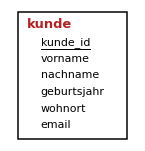

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">email</th></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">keine</td></tr>
<tr><td style="text-align: right">Luca</td><td style="text-align: right">luca.n@example.de</td></tr>
<tr><td style="text-align: right">Lina</td><td style="text-align: right">keine</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT vorname, CASE WHEN email IS NULL THEN 'keine' ELSE email END AS email FROM kunde WHERE wohnort = 'Senden';
```

</details>

#### Aufgabe 12.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```sql
SELECT LENGTH('Kino'), SUBSTR('Kinosaal', 5, 4), REPLACE('2026-11-02', '-', '.');
```

In [ ]:
SELECT LENGTH('Kino'), SUBSTR('Kinosaal', 5, 4), REPLACE('2026-11-02', '-', '.');

## 13. Gemischte Übungen

#### Aufgabe 13.1

Welcher Film hat die meisten Zuschauer? Gib Titel und Anzahl der Tickets aus (nur die erste Zeile).

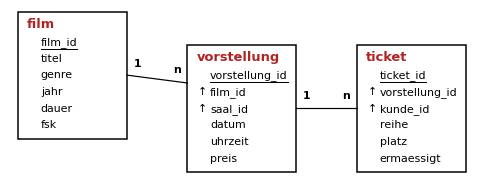

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">zuschauer</th></tr>
<tr><td style="text-align: right">Nachtzug nach Wien</td><td style="text-align: right">21</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel, COUNT(*) AS zuschauer
FROM ticket t
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
GROUP BY f.film_id
ORDER BY zuschauer DESC
LIMIT 1;
```

</details>

#### Aufgabe 13.2

Gib für jede Vorstellung am Samstag, dem 7. November, Uhrzeit, Saalname, verkaufte Tickets und die Auslastung in Prozent (eine Nachkommastelle) aus.
Auch Vorstellungen ohne Tickets sollen erscheinen. Nach Uhrzeit sortiert.

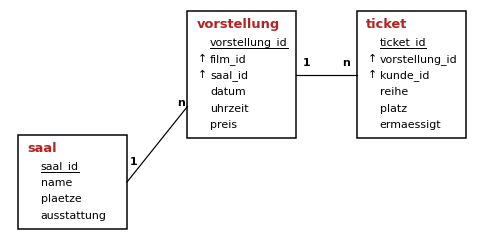

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">uhrzeit</th><th style="text-align: right">name</th><th style="text-align: right">tickets</th><th style="text-align: right">prozent</th></tr>
<tr><td style="text-align: right">14:30</td><td style="text-align: right">Großer Saal</td><td style="text-align: right">0</td><td style="text-align: right">0.0</td></tr>
<tr><td style="text-align: right">17:00</td><td style="text-align: right">Lounge</td><td style="text-align: right">6</td><td style="text-align: right">15.0</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">Blauer Saal</td><td style="text-align: right">6</td><td style="text-align: right">4.3</td></tr>
<tr><td style="text-align: right">20:00</td><td style="text-align: right">Roter Saal</td><td style="text-align: right">2</td><td style="text-align: right">2.2</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">Blauer Saal</td><td style="text-align: right">4</td><td style="text-align: right">2.9</td></tr>
<tr><td style="text-align: right">22:30</td><td style="text-align: right">Roter Saal</td><td style="text-align: right">2</td><td style="text-align: right">2.2</td></tr>
</table>

*6 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT v.uhrzeit, s.name, COUNT(t.ticket_id) AS tickets, ROUND(COUNT(t.ticket_id) * 100.0 / s.plaetze, 1) AS prozent
FROM vorstellung v
JOIN saal s ON v.saal_id = s.saal_id
LEFT JOIN ticket t ON t.vorstellung_id = v.vorstellung_id
WHERE v.datum = '2026-11-07'
GROUP BY v.vorstellung_id
ORDER BY v.uhrzeit;
```

</details>

#### Aufgabe 13.3

Gib Vorname und Nachname der Kunden aus, die Filme aus mindestens 5 verschiedenen Genres gesehen haben, mit der Anzahl der Genres.

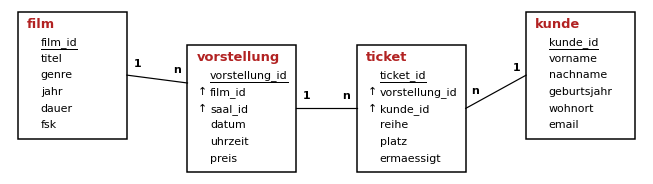

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th><th style="text-align: right">genres</th></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">Sophie</td><td style="text-align: right">Meyer</td><td style="text-align: right">6</td></tr>
<tr><td style="text-align: right">Lea</td><td style="text-align: right">Klein</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">Finn</td><td style="text-align: right">Wolf</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">Leon</td><td style="text-align: right">Krüger</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">Ella</td><td style="text-align: right">Hofmann</td><td style="text-align: right">5</td></tr>
<tr><td style="text-align: right">Theo</td><td style="text-align: right">Schmitt</td><td style="text-align: right">5</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT k.vorname, k.nachname, COUNT(DISTINCT f.genre) AS genres
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
GROUP BY k.kunde_id
HAVING genres >= 5;
```

</details>

#### Aufgabe 13.4

Gib für jedes Genre das Durchschnittsalter der Zuschauer im Jahr 2026 aus (eine Nachkommastelle), das jüngste Publikum zuerst.

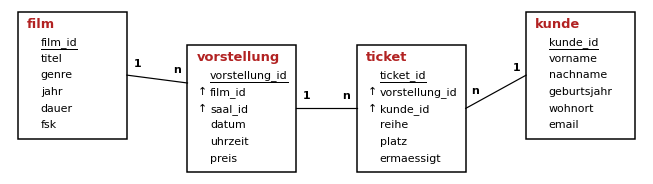

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">genre</th><th style="text-align: right">alter_schnitt</th></tr>
<tr><td style="text-align: right">Dokumentation</td><td style="text-align: right">23.2</td></tr>
<tr><td style="text-align: right">Science-Fiction</td><td style="text-align: right">24.5</td></tr>
<tr><td style="text-align: right">Action</td><td style="text-align: right">25.7</td></tr>
<tr><td style="text-align: right">Animation</td><td style="text-align: right">28.6</td></tr>
<tr><td style="text-align: right">Krimi</td><td style="text-align: right">32.5</td></tr>
<tr><td style="text-align: right">Komödie</td><td style="text-align: right">33.3</td></tr>
<tr><td style="text-align: right">Drama</td><td style="text-align: right">35.5</td></tr>
<tr><td style="text-align: right">Horror</td><td style="text-align: right">43.3</td></tr>
</table>

*8 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.genre, ROUND(AVG(2026 - k.geburtsjahr), 1) AS alter_schnitt
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
GROUP BY f.genre
ORDER BY alter_schnitt;
```

</details>

#### Aufgabe 13.5

Gib Vorname und Nachname aller Kunden aus, die zusammen mit Lena Hoffmann in einer Vorstellung waren (ohne Lena selbst), jeden nur einmal.

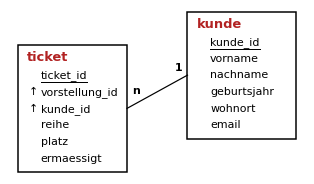

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">vorname</th><th style="text-align: right">nachname</th></tr>
<tr><td style="text-align: right">Hannah</td><td style="text-align: right">Koch</td></tr>
<tr><td style="text-align: right">Luca</td><td style="text-align: right">Neumann</td></tr>
<tr><td style="text-align: right">Jonas</td><td style="text-align: right">Becker</td></tr>
<tr><td style="text-align: right">Paul</td><td style="text-align: right">Wagner</td></tr>
<tr><td style="text-align: right">Noah</td><td style="text-align: right">Schneider</td></tr>
<tr><td style="text-align: right">Emma</td><td style="text-align: right">Fischer</td></tr>
<tr><td style="text-align: right">Ben</td><td style="text-align: right">Weber</td></tr>
<tr><td style="text-align: right">Leon</td><td style="text-align: right">Krüger</td></tr>
<tr><td style="text-align: right">Lea</td><td style="text-align: right">Klein</td></tr>
<tr><td style="text-align: right">Ida</td><td style="text-align: right">Braun</td></tr>
<tr><td style="text-align: right">Frieda</td><td style="text-align: right">Lange</td></tr>
<tr><td style="text-align: right">Theo</td><td style="text-align: right">Schmitt</td></tr>
<tr><td style="text-align: right">Finn</td><td style="text-align: right">Wolf</td></tr>
<tr><td style="text-align: right">Felix</td><td style="text-align: right">Zimmermann</td></tr>
</table>

*14 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT DISTINCT k.vorname, k.nachname
FROM kunde k JOIN ticket t ON t.kunde_id = k.kunde_id
WHERE t.vorstellung_id IN (SELECT t2.vorstellung_id
                           FROM ticket t2 JOIN kunde k2 ON t2.kunde_id = k2.kunde_id
                           WHERE k2.vorname = 'Lena' AND k2.nachname = 'Hoffmann')
  AND NOT (k.vorname = 'Lena' AND k.nachname = 'Hoffmann');
```

</details>

#### Aufgabe 13.6

Gib den Saal mit den höchsten Einnahmen (Summe der Preise aller Tickets, ohne Ermäßigung) mit den Einnahmen aus.

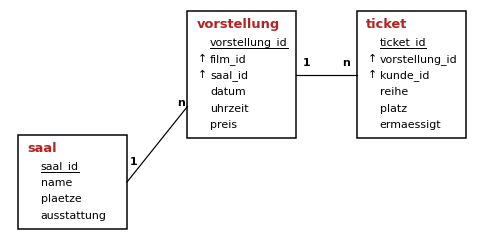

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">name</th><th style="text-align: right">einnahmen</th></tr>
<tr><td style="text-align: right">Lounge</td><td style="text-align: right">833.5</td></tr>
</table>

*1 Zeile*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT s.name, SUM(v.preis) AS einnahmen
FROM ticket t
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN saal s ON v.saal_id = s.saal_id
GROUP BY s.saal_id
ORDER BY einnahmen DESC
LIMIT 1;
```

</details>

#### Aufgabe 13.7

Gib Titel und Anzahl der Tickets aller Filme mit FSK 16 oder 18 aus, die von Kunden unter 25 Jahren (im Jahr 2026) gesehen wurden, nach Anzahl absteigend.

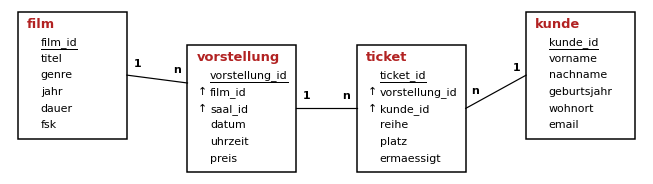

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">titel</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">Wolkenkratzer</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Kettenreaktion</td><td style="text-align: right">4</td></tr>
<tr><td style="text-align: right">Der Fluch von Burg Eisenstein</td><td style="text-align: right">1</td></tr>
</table>

*3 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT f.titel, COUNT(*) AS tickets
FROM kunde k
JOIN ticket t ON t.kunde_id = k.kunde_id
JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
JOIN film f ON v.film_id = f.film_id
WHERE f.fsk >= 16 AND 2026 - k.geburtsjahr < 25
GROUP BY f.film_id
ORDER BY tickets DESC;
```

</details>

#### Aufgabe 13.8

Gib für jeden Wochentag (Spalte `wochentag` mit `strftime('%w', datum)`) die Zahl der verkauften Tickets aus, nach Wochentag sortiert.

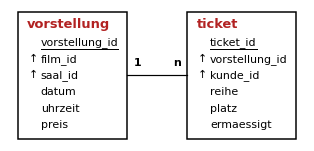

**Erwartete Ausgabe:**

<table style="margin-left: 0">
<tr><th style="text-align: right">wochentag</th><th style="text-align: right">tickets</th></tr>
<tr><td style="text-align: right">0</td><td style="text-align: right">17</td></tr>
<tr><td style="text-align: right">1</td><td style="text-align: right">27</td></tr>
<tr><td style="text-align: right">2</td><td style="text-align: right">16</td></tr>
<tr><td style="text-align: right">3</td><td style="text-align: right">28</td></tr>
<tr><td style="text-align: right">4</td><td style="text-align: right">11</td></tr>
<tr><td style="text-align: right">5</td><td style="text-align: right">11</td></tr>
<tr><td style="text-align: right">6</td><td style="text-align: right">20</td></tr>
</table>

*7 Zeilen*

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```sql
SELECT strftime('%w', v.datum) AS wochentag, COUNT(*) AS tickets
FROM ticket t JOIN vorstellung v ON t.vorstellung_id = v.vorstellung_id
GROUP BY wochentag
ORDER BY wochentag;
```

</details>